# Análisis descriptivo del mercado: empresas del Dow Jones (2016-2025)

Dataset de entrada:
- `Datos/Transformados/dowjones_diario_2016_2025.csv` -> dataset limpio: una vela diaria
  (open, high, low, close, volume) por empresa y día de mercado, precios ajustados por splits.

Dataset de salida:
- `Datos/Transformados/resumen_descriptivo_empresas.csv` -> una fila por empresa con sus métricas de
  rentabilidad, riesgo y relación con el mercado.

Objetivo: describir **el mercado en su conjunto**, no cada acción por separado.

El orden va de menos a más técnico:

| # | Sección | Qué responde |
|---|---|---|
| 1 | Panorama del universo | Qué empresas, de qué sectores y con qué historial |
| 2 | Evolución del mercado | Cómo se ha comportado el conjunto y frente al Dow Jones real |
| 3 | Rentabilidad por empresa y año | Quién ha ganado y quién ha perdido, y cuándo |
| 4 | Volumen negociado | Dónde está la liquidez y cuándo se dispara |
| 5 | Rentabilidades diarias | Cómo se distribuyen: medias, colas, días extremos |
| 6 | Volatilidad | Cuánto riesgo hay y cómo cambia en el tiempo |
| 7 | Riesgo frente a rentabilidad | Qué empresas compensan su riesgo (Sharpe, Sortino) |
| 8 | Drawdowns | Cuánto se puede llegar a perder y cuánto se tarda en recuperar |
| 9 | Correlaciones | Cuánto se mueven juntas y si eso cambia en las crisis |
| 10 | Beta frente al mercado | Sensibilidad de cada empresa al mercado |
| 11 | Factores del mercado (PCA) | Cuántos factores mueven el mercado |
| 12 | Tabla resumen | Todas las métricas juntas, una fila por empresa |

**Decisiones de partida (afectan a cómo se leen todos los resultados):**

- **Rentabilidad de precio, no total.** El cierre viene ajustado por splits pero no por dividendos.
  En empresas con dividendo alto (KO, PG, JNJ, CVX, IBM...) la rentabilidad total es
  bastante mayor. En la sección 3 se compara con el `Adj Close` de Yahoo si se puede descargar.
- **"Mercado" = índice propio equiponderado** de todas las empresas del dataset (media diaria de sus rentabilidades).
  Siempre está disponible y pesa igual a todas. Se compara con el `^DJI` real, que pondera por precio.
- **No es el Dow Jones de todo el periodo.** Las empresas del dataset son una foto fija de su composición,
  pero el índice ha cambiado varias veces entre 2016 y 2025 (entradas y salidas de miembros). Hay, por tanto,
  sesgo de composición: conviene comprobar los cambios del índice antes de citarlos. Además, son miembros
  recientes del índice, y mirar hacia atrás con ellas favorece a las que mejor lo han hecho (sesgo de supervivencia).
- **Rentabilidades simples** para construir índices y acumular, y para Sharpe, Sortino y beta; **logarítmicas**
  para estadísticos, volatilidad, correlaciones y PCA.

In [1]:
import os
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import kaleido
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Patch
from scipy import stats
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
import yfinance as yf

warnings.filterwarnings("ignore", category=RuntimeWarning)

C:\Users\Personal\.conda\envs\BDA\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
# Rutas y parámetros
RUTA_DATOS = "Datos/Transformados/dowjones_diario_2016_2025.csv"
RUTA_TRANSFORMADOS = "Datos/Transformados"
FECHA_INICIO = "2016-01-01"
FECHA_FIN = "2026-01-01"          # exclusivo en yfinance (incluye hasta 2025-12-31)

DIAS_ANIO = 252                   # sesiones por año para anualizar
TASA_LIBRE_DEFECTO = 0.02         # solo si no se puede descargar la letra del Tesoro (^IRX)
VENTANA_CORTA, VENTANA_LARGA = 21, 63   # ~1 mes y ~1 trimestre de sesiones

# Episodios de caída del mercado que se sombrean en los gráficos (fechas aproximadas del Dow Jones)
EPISODIOS = {
    "Ventas fin 2018": ("2018-10-03", "2018-12-24"),
    "COVID-19": ("2020-02-12", "2020-03-23"),
    "Subida de tipos": ("2022-01-04", "2022-09-30"),
    "Aranceles 2025": ("2025-04-02", "2025-04-08"),
}

In [3]:
# Estilo de los gráficos: la paleta y el estilo base vienen de packages/bbva_graficos.py
from packages.bbva_graficos import (configurar_graficos, guardar_mpl, guardar_plotly, formato_es, imprimir,
                                    texto_es, BBVA, PALETA, CMAP_DIVERGENTE, FUENTE)
configurar_graficos()

AZUL = BBVA["principal"]       # serie principal
NARANJA = BBVA["agua"]         # segunda serie / referencia (nombre histórico de la variable)
GRIS = BBVA["gris_dato"]       # series de apoyo
ROJO = BBVA["marino"]          # caídas y valores negativos (la paleta BBVA no usa rojo)
FONDO, TINTA, TINTA_2 = BBVA["blanco"], BBVA["marino"], BBVA["marino"]
# Ajustes puntuales de este notebook: gráficos densos, con títulos y líneas algo más pequeños que el global
# (el texto se queda en 11 pt, el mínimo de legibilidad)
plt.rcParams.update({
    "grid.linewidth": 0.6, "axes.titlesize": 12, "figure.titlesize": 13,
    "figure.titleweight": "bold", "lines.linewidth": 2, "font.size": 11,
    "xtick.labelsize": 11, "ytick.labelsize": 11, "axes.labelsize": 11, "legend.fontsize": 11,
})
pd.set_option("display.width", 200)

# Sectores: un color fijo por sector, siempre el mismo en todos los gráficos.
# Energía, Comunicación y Materiales tienen una sola empresa cada uno y se agrupan en "Otros".
# Consumo básico y discrecional se agrupan en "Consumo" para no pasar de 5 colores (paleta BBVA).
SECTOR = {
    "AAPL": "Tecnología", "CRM": "Tecnología", "CSCO": "Tecnología", "IBM": "Tecnología",
    "INTC": "Tecnología", "MSFT": "Tecnología",
    "AXP": "Financiero", "GS": "Financiero", "JPM": "Financiero", "TRV": "Financiero",
    "V": "Financiero",            # GICS la pasó de Tecnología a Financiero en 2023
    "AMGN": "Salud", "JNJ": "Salud", "MRK": "Salud", "UNH": "Salud",
    "BA": "Industrial", "CAT": "Industrial", "MMM": "Industrial",
    "HD": "Consumo", "MCD": "Consumo", "NKE": "Consumo",
    "KO": "Consumo", "PG": "Consumo",
    "CVX": "Otros", "DIS": "Otros", "DOW": "Otros",
    # Otros miembros del Dow en 2016-2025, por si el dataset los incluye
    "HON": "Industrial", "NVDA": "Tecnología", "AMZN": "Consumo", "WMT": "Consumo",
    "WBA": "Consumo", "VZ": "Otros", "SHW": "Otros", "XOM": "Otros", "PFE": "Salud",
    "RTX": "Industrial", "UTX": "Industrial", "GE": "Industrial", "DD": "Otros", "DWDP": "Otros",
}
SUBSECTOR_OTROS = {"CVX": "Energía", "DIS": "Comunicación", "DOW": "Materiales", "VZ": "Comunicación",
                   "SHW": "Materiales", "XOM": "Energía", "DD": "Materiales", "DWDP": "Materiales"}
COLOR_SECTOR = {
    # ordenados por número de empresas (de mayor a menor); cada sector mantiene su color
    "Tecnología": PALETA[0], "Financiero": PALETA[1], "Consumo": PALETA[4], "Salud": PALETA[2],
    "Industrial": PALETA[3], "Otros": BBVA["gris_dato"],
}
NOMBRE = {
    "AAPL": "Apple", "AMGN": "Amgen", "AXP": "American Express", "BA": "Boeing", "CAT": "Caterpillar",
    "CRM": "Salesforce", "CSCO": "Cisco", "CVX": "Chevron", "DIS": "Disney", "DOW": "Dow Inc.",
    "GS": "Goldman Sachs", "HD": "Home Depot", "IBM": "IBM", "INTC": "Intel", "JNJ": "Johnson & Johnson",
    "JPM": "JPMorgan", "KO": "Coca-Cola", "MCD": "McDonald's", "MMM": "3M", "MRK": "Merck",
    "MSFT": "Microsoft", "NKE": "Nike", "PG": "Procter & Gamble", "TRV": "Travelers",
    "UNH": "UnitedHealth", "V": "Visa", "HON": "Honeywell", "NVDA": "Nvidia", "AMZN": "Amazon",
    "WMT": "Walmart", "WBA": "Walgreens", "VZ": "Verizon", "SHW": "Sherwin-Williams", "XOM": "ExxonMobil",
    "PFE": "Pfizer", "RTX": "RTX", "UTX": "United Technologies", "GE": "General Electric", "DD": "DuPont",
    "DWDP": "DowDuPont",
}

# Divergente azul marino (negativo) - blanco (cero) - aguamarina (positivo): la escala del módulo
DIVERGENTE = CMAP_DIVERGENTE




def color(ticker):
    return COLOR_SECTOR[SECTOR.get(ticker, "Otros")]


def sombrear_episodios(ax, etiquetas=False, izquierda=(), abajo=()):
    """Sombrea los episodios de caída; con etiquetas=True escribe el nombre arriba.

    izquierda / abajo: episodios cuya etiqueta se pasa a la izquierda del tramo o al pie del gráfico
    cuando en su sitio normal taparía la serie."""
    for nombre, (ini, fin) in EPISODIOS.items():
        ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fin), color=GRIS, alpha=0.13, lw=0)
        if etiquetas:
            x, ha = pd.Timestamp(ini), "left"
            if nombre in izquierda:
                x, ha = pd.Timestamp(ini) - pd.Timedelta(days=6), "right"
            ax.text(x, 0.01 if nombre in abajo else 0.99, nombre, transform=ax.get_xaxis_transform(),
                    fontsize=11, color=TINTA_2, va="bottom" if nombre in abajo else "top", ha=ha, rotation=90,
                    bbox=dict(facecolor=FONDO, edgecolor="none", alpha=0.7, pad=1), zorder=1)


def leyenda_sectores(ax, **kwargs):
    """Leyenda de sectores; por defecto fuera del gráfico, a la derecha, para no tapar barras."""
    opciones = {"loc": "center left", "bbox_to_anchor": (1.01, 0.5), "fontsize": 8.5, **kwargs}
    ax.legend(handles=[Patch(color=c, label=s) for s, c in COLOR_SECTOR.items()], **opciones)


def eje_pct(ax, eje="y", decimales=0):
    formato = mtick.PercentFormatter(1, decimals=decimales)
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(formato)


def descargar_yahoo(tickers, campos):
    """Descarga de Yahoo los campos pedidos. Devuelve {campo: DataFrame} o None si no se puede."""
    if yf is None:
        imprimir("yfinance no está instalado: se omite la comparación con Yahoo.")
        return None
    try:
        datos = yf.download(tickers, start=FECHA_INICIO, end=FECHA_FIN, auto_adjust=False,
                            progress=False, threads=True)
        if datos is None or datos.empty:
            raise ValueError("descarga vacía")
        salida = {}
        for campo in campos:
            tabla = datos[campo]
            if isinstance(tabla, pd.Series):
                tabla = tabla.to_frame(tickers[0])
            indice = pd.to_datetime(tabla.index)
            if indice.tz is not None:
                indice = indice.tz_convert(None)
            tabla.index = indice.normalize()
            salida[campo] = tabla
        return salida
    except Exception as error:
        imprimir(f"No se pudo descargar {tickers[:3]}... de Yahoo ({error}): se omite esa comparación.")
        return None


# Gráficos interactivos (plotly) en el notebook: los gráficos 12, 13 y 16, que son los que más se exploran
CONFIG_PLOTLY = {"displaylogo": False}
pio.renderers.default = "vscode"
# kaleido falla en Windows dentro de Jupyter al abrir y cerrar el navegador en cada exportación a PNG:
# se deja un servidor abierto durante la sesión, que es el que usa guardar_plotly
kaleido.start_sync_server(silence_warnings=True)
warnings.filterwarnings("ignore", message="The kopts argument is ignored")


def fechas_plotly(fig):
    """Eje X de fechas con números según el zoom (sin nombres de mes en inglés)."""
    dia, anio = 86_400_000, 31_536_000_000
    fig.update_xaxes(tickformatstops=[dict(dtickrange=[None, 27 * dia], value="%d/%m/%Y"),
                                      dict(dtickrange=[27 * dia, 0.9 * anio], value="%m/%Y"),
                                      dict(dtickrange=[0.9 * anio, None], value="%Y")])


def guardar_interactivo(fig, nombre, ancho=1200, alto=500, margen=80):
    """Añade la fuente, guarda el PNG en Graficos/ como el resto y muestra el gráfico interactivo.

    margen: espacio inferior en píxeles; la fuente se escribe al final de ese espacio."""
    fig.add_annotation(text=f"Fuente: {FUENTE}", xref="paper", yref="paper", x=0, y=0, yshift=-(margen - 25),
                       xanchor="left", yanchor="top", showarrow=False, font=dict(size=12, color=TINTA))
    fig.update_layout(separators=",.", height=alto, margin=dict(b=margen))
    guardar_plotly(fig, nombre, ancho, alto)
    fig.show(config=CONFIG_PLOTLY)

# 1. Panorama del universo: qué empresas, de qué sectores y con qué historial

In [4]:
df = pd.read_csv(RUTA_DATOS, parse_dates=["date"]).sort_values(["symbol", "date"])
empresas = sorted(df["symbol"].unique())
imprimir(f"{len(df):,} filas | {len(empresas)} empresas | {df['date'].min().date()} a {df['date'].max().date()}")
imprimir("Nulos:", int(df.isna().sum().sum()), "| Duplicados symbol+date:", int(df.duplicated(["symbol", "date"]).sum()))

# Tablas anchas (una columna por empresa): son la base de todo el análisis
precios = df.pivot(index="date", columns="symbol", values="close").sort_index()
volumen = df.pivot(index="date", columns="symbol", values="volume").sort_index()
rent = precios.pct_change(fill_method=None)            # rentabilidad simple diaria
rent_log = np.log(precios).diff()                       # rentabilidad logarítmica diaria

desconocidas = [t for t in empresas if t not in SECTOR]
if desconocidas:
    imprimir("Empresas sin sector asignado (van a 'Otros'; añádelas a SECTOR si quieres):", desconocidas)
SECTOR = {t: SECTOR.get(t, "Otros") for t in empresas}       # solo las empresas del dataset
NOMBRE = {t: NOMBRE.get(t, t) for t in empresas}
COLOR_SECTOR = {s: c for s, c in COLOR_SECTOR.items() if s in SECTOR.values()}   # solo sectores presentes
N = len(empresas)
orden_sector = sorted(empresas, key=lambda t: (list(COLOR_SECTOR).index(SECTOR[t]), t))
imprimir(f"{N} empresas:", ", ".join(orden_sector))

64.557 filas | 26 empresas | 2016-01-04 a 2025-12-31
Nulos: 0 | Duplicados symbol+date: 0
26 empresas: AAPL, CRM, CSCO, IBM, INTC, MSFT, AXP, GS, JPM, TRV, V, HD, KO, MCD, NKE, PG, AMGN, JNJ, MRK, UNH, BA, CAT, MMM, CVX, DIS, DOW


In [5]:
panorama = df.groupby("symbol").agg(
    inicio=("date", "min"), fin=("date", "max"), sesiones=("date", "size"),
    precio_inicial=("close", "first"), precio_final=("close", "last"))
panorama.insert(0, "nombre", panorama.index.map(NOMBRE))
panorama.insert(1, "sector", panorama.index.map(lambda t: SUBSECTOR_OTROS.get(t, SECTOR[t])))
panorama["inicio"] = panorama["inicio"].dt.date
panorama["fin"] = panorama["fin"].dt.date
imprimir(panorama.loc[orden_sector].round(2).to_string())

sesiones_anio = precios.notna().groupby(precios.index.year).sum()
imprimir("\nSesiones por año (mínimo y máximo entre empresas):")
imprimir(sesiones_anio.agg(["min", "max"], axis=1).T.to_string())

                   nombre        sector      inicio         fin  sesiones  precio_inicial  precio_final
symbol                                                                                                 
AAPL                Apple    Tecnología  2016-01-04  2025-12-31      2514           26,34        271,86
CRM            Salesforce    Tecnología  2016-01-04  2025-12-31      2514           76,71        264,91
CSCO                Cisco    Tecnología  2016-01-04  2025-12-31      2514           26,41         77,03
IBM                   IBM    Tecnología  2016-01-04  2025-12-31      2514          129,97        296,21
INTC                Intel    Tecnología  2016-01-04  2025-12-31      2514           33,99         36,90
MSFT            Microsoft    Tecnología  2016-01-04  2025-12-31      2514           54,80        483,62
AXP      American Express    Financiero  2016-01-04  2025-12-31      2514           67,59        369,95
GS          Goldman Sachs    Financiero  2016-01-04  2025-12-31 


Sesiones por año (mínimo y máximo entre empresas):
date  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025
min      0     0     0   199   253   252   251   250   252   250
max    252   251   251   252   253   252   251   250   252   250


Guardado: Graficos\descriptivo_g01_composicion_sectorial.png


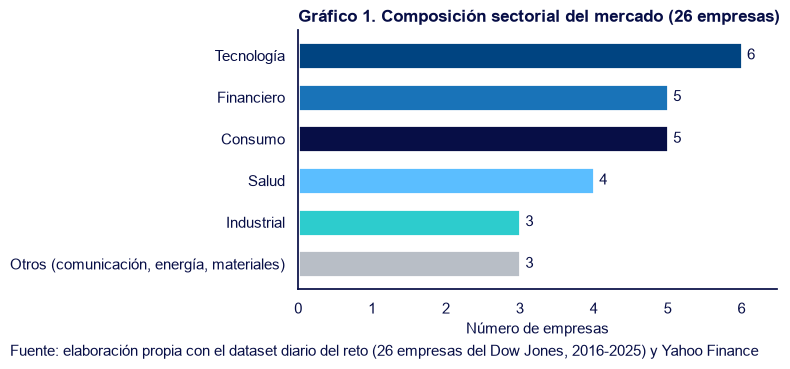

In [6]:
# Gráfico: cuántas empresas hay de cada sector
conteo = pd.Series(SECTOR).value_counts().reindex(COLOR_SECTOR)[::-1]
etiquetas = [s if s != "Otros" else "Otros (" + ", ".join(sorted({SUBSECTOR_OTROS.get(t, NOMBRE[t]).lower() for t in empresas if SECTOR[t] == "Otros"})) + ")" for s in conteo.index]
fig, ax = plt.subplots(figsize=(8, 3.6))
barras = ax.barh(etiquetas, conteo.values, color=[COLOR_SECTOR[s] for s in conteo.index],
                 height=0.65, edgecolor=FONDO, linewidth=2)
ax.bar_label(barras, padding=4, color=TINTA_2, fontsize=11)
ax.set_xlabel("Número de empresas")
ax.grid(False)
ax.margins(x=0.08)
ax.set_title(f"Gráfico 1. Composición sectorial del mercado ({N} empresas)")
plt.tight_layout()
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g01_composicion_sectorial")
plt.show()

**Qué se observa:** los dos sectores principales son el tecnológico (6 empresas) y el financiero (5), que suman 11 de las 26 empresas (un 42 %). Les siguen consumo (5: HD, MCD y NKE, de consumo discrecional, y KO y PG, de consumo básico, agrupadas para no pasar de cinco colores), salud (4) e industrial (3). "Otros" agrupa las 3 empresas de energía, comunicación y materiales (CVX, DIS y DOW). Todas las empresas tienen historial completo desde enero de 2016 salvo DOW, que cotiza desde marzo de 2019, así que sus métricas no son del todo comparables con las demás.

# 2. Evolución del mercado: índice propio frente al Dow Jones real

In [7]:
# Índice equiponderado: cada día, media de las rentabilidades de las empresas que cotizan
rent_mercado = rent.mean(axis=1, skipna=True).iloc[1:]
indice_ew = 100 * (1 + rent_mercado).cumprod()
indice_ew = pd.concat([pd.Series([100.0], index=[precios.index[0]]), indice_ew])
rent_log_mercado = np.log1p(rent_mercado)

# Dow Jones real, rebasado a 100 el primer día, para comparar
yahoo_dji = descargar_yahoo(["^DJI"], ["Close"])
dji = None
if yahoo_dji is not None:
    dji = yahoo_dji["Close"]["^DJI"].reindex(precios.index).ffill().dropna()
    dji = 100 * dji / dji.iloc[0]

Guardado: Graficos\descriptivo_g02_evolucion_mercado.png


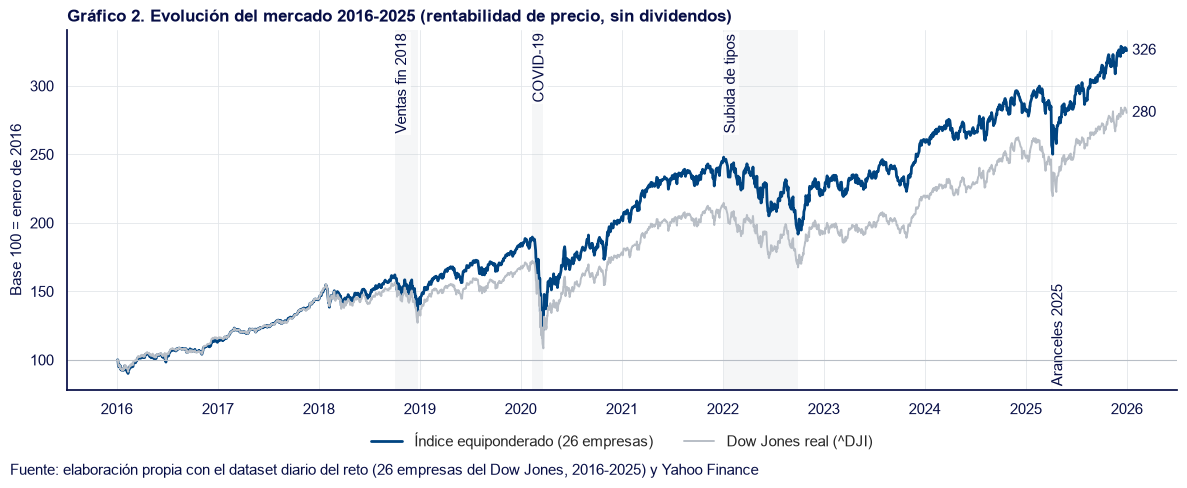

In [8]:
fig, ax = plt.subplots(figsize=(12, 4.8))
sombrear_episodios(ax, etiquetas=True, abajo=("Aranceles 2025",))
ax.plot(indice_ew, color=AZUL, lw=2, label=f"Índice equiponderado ({N} empresas)")
if dji is not None:
    ax.plot(dji, color=GRIS, lw=1.4, label="Dow Jones real (^DJI)")
for serie, col in [(indice_ew, AZUL)] + ([(dji, GRIS)] if dji is not None else []):
    ax.annotate(f"{serie.iloc[-1]:.0f}", (serie.index[-1], serie.iloc[-1]), xytext=(4, 0),
                textcoords="offset points", fontsize=11, color=TINTA_2, va="center")
ax.axhline(100, color=GRIS, lw=0.8)
ax.set_ylabel("Base 100 = enero de 2016")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
ax.set_title("Gráfico 2. Evolución del mercado 2016-2025 (rentabilidad de precio, sin dividendos)")
plt.tight_layout()
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g02_evolucion_mercado")
plt.show()

      equiponderado  dow_jones_real
date                               
2016           12,8            15,2
2017           27,5            25,1
2018            1,0            -5,6
2019           26,2            22,3
2020           11,6             7,2
2021           19,3            18,7
2022           -8,6            -8,8
2023           16,9            13,7
2024            8,5            12,9
2025           15,2            13,0

Rentabilidad anualizada (CAGR): equiponderado 12,5 % | Dow Jones real 10,9 %


Guardado: Graficos\descriptivo_g03_rentabilidad_anual_indice.png


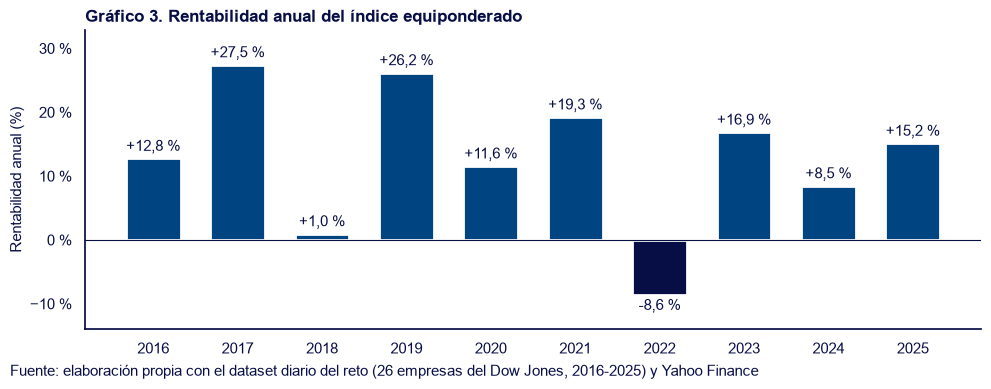

In [9]:
# Rentabilidad anual del mercado (índice equiponderado) y del Dow Jones real
anuales = pd.DataFrame({
    "equiponderado": (1 + rent_mercado).groupby(rent_mercado.index.year).prod() - 1,
})
if dji is not None:
    anuales["dow_jones_real"] = dji.groupby(dji.index.year).last() / dji.groupby(dji.index.year).last().shift() - 1
    anuales.loc[anuales.index.min(), "dow_jones_real"] = dji.groupby(dji.index.year).last().iloc[0] / 100 - 1
imprimir((anuales * 100).round(1).to_string())

anios_total = (indice_ew.index[-1] - indice_ew.index[0]).days / 365.25
imprimir(f"\nRentabilidad anualizada (CAGR): equiponderado {(indice_ew.iloc[-1] / 100) ** (1 / anios_total) - 1:.1%}"
      + (f" | Dow Jones real {(dji.iloc[-1] / 100) ** (1 / anios_total) - 1:.1%}" if dji is not None else ""))

fig, ax = plt.subplots(figsize=(10, 3.8))
valores = anuales["equiponderado"]
barras = ax.bar(valores.index.astype(str), valores, color=np.where(valores >= 0, AZUL, ROJO),
                width=0.65, edgecolor=FONDO, linewidth=2)
ax.bar_label(barras, labels=[f"{v:+.1%}" for v in valores], padding=3, fontsize=11, color=TINTA_2)
ax.axhline(0, color=TINTA_2, lw=0.8)
ax.margins(y=0.15)
eje_pct(ax)
ax.grid(False)
ax.set_ylabel("Rentabilidad anual (%)")
ax.set_title("Gráfico 3. Rentabilidad anual del índice equiponderado")
plt.tight_layout()
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g03_rentabilidad_anual_indice")
plt.show()

**Qué se observa:**
- El índice equiponderado de las 26 empresas pasa de 100 a 326 (+12,5 % anual) y el Dow Jones real de 100 a 280 (+10,9 % anual). Hasta principios de 2018 las dos curvas casi se superponen; después se separan, con diferencias anuales de entre −4,4 puntos (2024) y +6,6 puntos (2018: +1,0 % frente a −5,6 %). El universo del dataset sigue bien la forma y las caídas del Dow, pero rinde algo más (composición y ponderación distintas).
- Solo hay un año negativo: 2022 (−8,6 %; el Dow, −8,8 %), el único en el que más de la mitad de las empresas pierde. Los otros episodios sombreados (finales de 2018, COVID-19, aranceles de 2025) fueron caídas dentro del año, no años de pérdidas: 2018 cerró en +1,0 % y 2020 en +11,6 %, porque el mercado se recuperó antes de diciembre.
- Los mejores años son 2017 (+27,5 %) y 2019 (+26,2 %); 2018 (+1,0 %) y 2024 (+8,5 %) son los más flojos entre los positivos.

# 3. Rentabilidad por empresa y año: quién ha ganado, quién ha perdido y cuándo

Guardado: Graficos\descriptivo_g04_empresas_frente_al_mercado.png


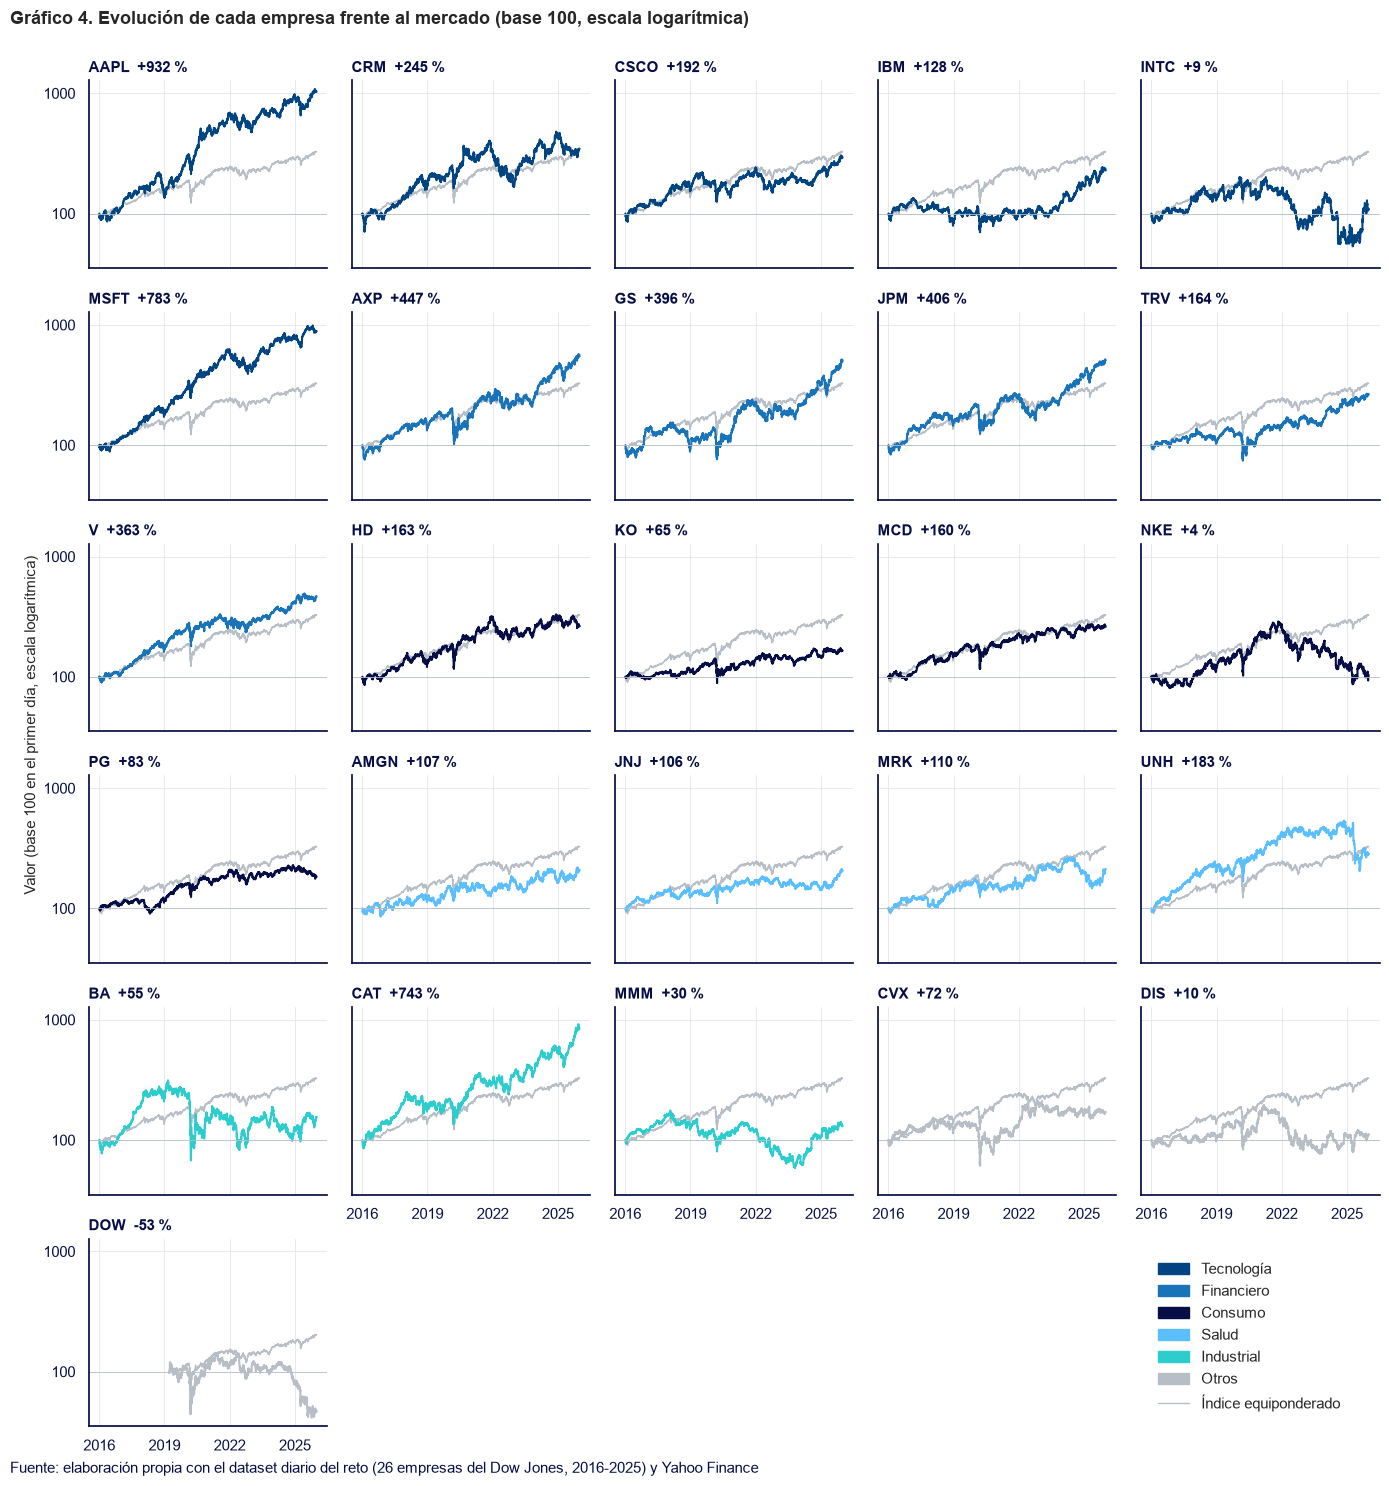

In [10]:
# Pequeños múltiplos: cada empresa (color de su sector) frente al índice (gris), base 100 en su primer día
columnas = 5
filas = int(np.ceil(N / columnas))
fig, ejes = plt.subplots(filas, columnas, figsize=(14, 2.4 * filas + 0.5), sharex=True, sharey=True, squeeze=False)
for ax, ticker in zip(ejes.flat, orden_sector):
    serie = precios[ticker].dropna()
    base_indice = indice_ew.loc[serie.index[0]:]
    ax.plot(100 * base_indice / base_indice.iloc[0], color=GRIS, lw=1)
    ax.plot(100 * serie / serie.iloc[0], color=color(ticker), lw=1.5)
    ax.set_yscale("log")
    ax.set_title(f"{ticker}  {serie.iloc[-1] / serie.iloc[0] - 1:+.0%}", fontsize=11)
    ax.axhline(100, color=GRIS, lw=0.6)
for ax in list(ejes.flat)[len(orden_sector):]:
    ax.set_visible(False)
for ax in list(ejes.flat)[len(orden_sector) - columnas:len(orden_sector)]:
    ax.tick_params(labelbottom=True)
ejes[0, 0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
for ax in ejes.flat:
    ax.xaxis.set_major_locator(mdates.YearLocator(3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.legend(handles=[Patch(color=c, label=s) for s, c in COLOR_SECTOR.items()]
           + [plt.Line2D([], [], color=GRIS, lw=1, label="Índice equiponderado")],
           loc="lower right", bbox_to_anchor=(0.97, 0.03), ncol=1, fontsize=11)
fig.suptitle("Gráfico 4. Evolución de cada empresa frente al mercado (base 100, escala logarítmica)",
             x=0.01, ha="left")
fig.supylabel("Valor (base 100 en el primer día, escala logarítmica)", fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.98))
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g04_empresas_frente_al_mercado")
plt.show()

Guardado: Graficos\descriptivo_g05_cagr_por_empresa.png


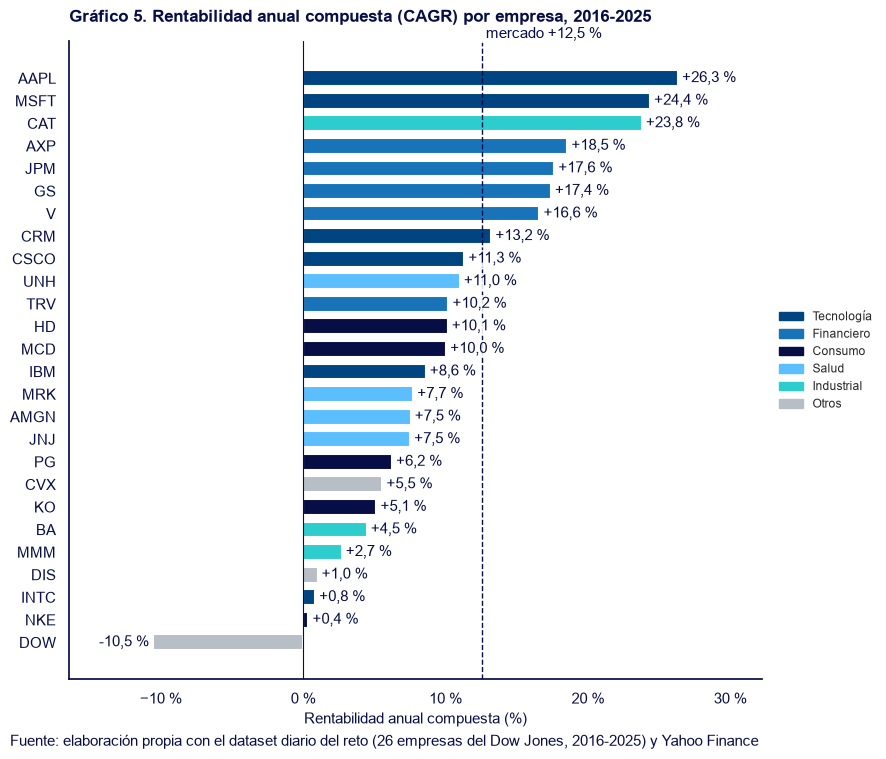

In [11]:
def cagr(serie):
    """Rentabilidad anual compuesta entre el primer y el último precio disponibles."""
    s = serie.dropna()
    anios = (s.index[-1] - s.index[0]).days / 365.25
    return (s.iloc[-1] / s.iloc[0]) ** (1 / anios) - 1


cagr_empresas = precios.apply(cagr).sort_values()
cagr_mercado = cagr(indice_ew)

fig, ax = plt.subplots(figsize=(9, 7.5))
barras = ax.barh(cagr_empresas.index, cagr_empresas, color=[color(t) for t in cagr_empresas.index],
                 height=0.7, edgecolor=FONDO, linewidth=1.5)
ax.bar_label(barras, labels=[f"{v:+.1%}" for v in cagr_empresas], padding=3, fontsize=11, color=TINTA_2)
ax.axvline(cagr_mercado, color=TINTA_2, lw=1, ls="--")
ax.text(cagr_mercado, 1.0, f" mercado {cagr_mercado:+.1%}", transform=ax.get_xaxis_transform(),
        fontsize=11, color=TINTA_2, va="bottom")
ax.axvline(0, color=TINTA_2, lw=0.8)
eje_pct(ax, "x")
ax.grid(False)
ax.set_xlabel("Rentabilidad anual compuesta (%)")
ax.margins(x=0.16)
leyenda_sectores(ax)
ax.set_title("Gráfico 5. Rentabilidad anual compuesta (CAGR) por empresa, 2016-2025", pad=14)
plt.tight_layout()
for t in ax.texts:
    t.set_bbox(dict(facecolor=FONDO, edgecolor="none", alpha=0.85, pad=1))
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g05_cagr_por_empresa")
plt.show()

Guardado: Graficos\descriptivo_g06_rentabilidad_anual_por_empresa.png


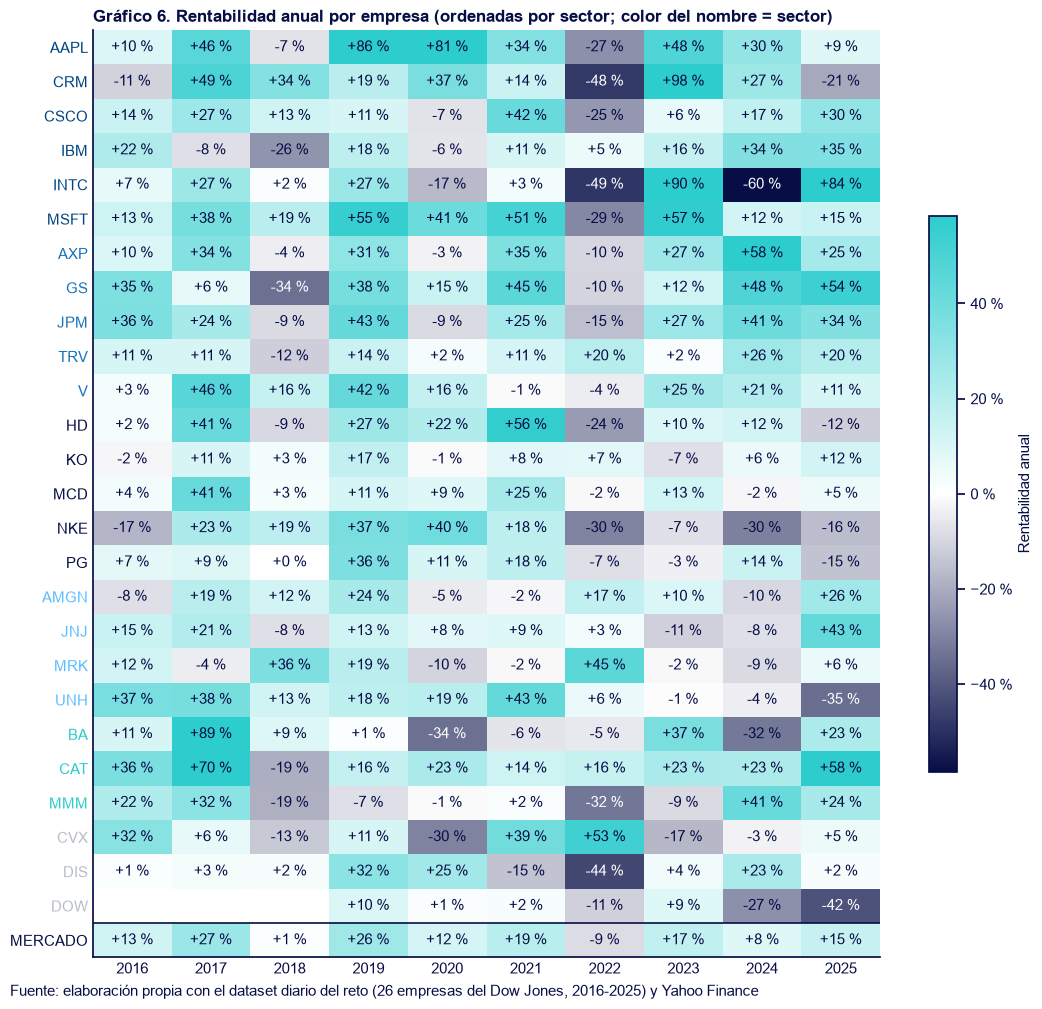

Años en los que más de la mitad de las empresas pierde: [2022]


In [12]:
# Rentabilidad de cada año por empresa (DOW: 2019 parcial, desde el 20/03)
anual_empresas = (1 + rent).groupby(rent.index.year).prod(min_count=1) - 1
anual_empresas = anual_empresas.where(precios.notna().groupby(precios.index.year).sum() > 1)
tabla = anual_empresas[orden_sector].T
tabla.loc["MERCADO"] = anuales["equiponderado"]

limite = np.nanpercentile(np.abs(tabla.values), 97)
fig, ax = plt.subplots(figsize=(11, 10))
imagen = ax.imshow(tabla.values, cmap=DIVERGENTE, norm=TwoSlopeNorm(0, -limite, limite), aspect="auto")
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        v = tabla.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:+.0%}", ha="center", va="center", fontsize=11,
                    color="white" if v < -0.55 * limite else TINTA)
ax.set_xticks(range(tabla.shape[1]), tabla.columns)
ax.set_yticks(range(tabla.shape[0]), tabla.index)
ax.axhline(tabla.shape[0] - 1.5, color=TINTA, lw=1.2)
for etiqueta in ax.get_yticklabels()[:-1]:
    etiqueta.set_color(color(etiqueta.get_text()))
ax.grid(False)
ax.tick_params(length=0)
fig.colorbar(imagen, ax=ax, format=mtick.PercentFormatter(1, 0), shrink=0.6, label="Rentabilidad anual")
ax.set_title("Gráfico 6. Rentabilidad anual por empresa (ordenadas por sector; color del nombre = sector)")
plt.tight_layout()
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g06_rentabilidad_anual_por_empresa")
plt.show()

imprimir("Años en los que más de la mitad de las empresas pierde:",
      [int(a) for a, v in (anual_empresas < 0).mean(axis=1).items() if v > 0.5])

In [13]:
# Rentabilidad de precio frente a rentabilidad total (con dividendos), si Yahoo está disponible
yahoo_empresas = descargar_yahoo(empresas, ["Adj Close", "Volume"])
if yahoo_empresas is not None:
    ajustado = yahoo_empresas["Adj Close"].reindex(columns=empresas)
    comparacion_div = pd.DataFrame({
        "cagr_precio": cagr_empresas,
        "cagr_total": ajustado.apply(cagr),
    })
    comparacion_div["aporte_dividendo"] = comparacion_div["cagr_total"] - comparacion_div["cagr_precio"]
    comparacion_div = comparacion_div.sort_values("aporte_dividendo", ascending=False)
    imprimir((comparacion_div * 100).round(2).to_string())
    imprimir(f"\nAporte medio del dividendo: {comparacion_div['aporte_dividendo'].mean():.2%} al año")

      cagr_precio  cagr_total  aporte_dividendo
DOW        -10,55       -5,42              5,12
IBM          8,59       13,31              4,72
CVX          5,55       10,17              4,62
MMM          2,69        6,14              3,45
CSCO        11,31       14,71              3,40
MRK          7,72       11,10              3,38
KO           5,13        8,49              3,36
AMGN         7,54       10,79              3,25
JPM         17,63       20,78              3,15
CAT         23,78       26,85              3,07
JNJ          7,50       10,52              3,02
PG           6,23        9,19              2,96
MCD         10,03       12,75              2,71
HD          10,14       12,80              2,66
TRV         10,19       12,64              2,44
GS          17,39       19,82              2,43
INTC         0,83        3,23              2,40
UNH         10,99       12,79              1,79
AXP         18,55       20,27              1,72
MSFT        24,35       26,02           

**Qué se observa:**
- **Dispersión muy grande.** De AAPL (+26,3 % anual, un +932 % en el periodo) a DOW (−10,5 % anual, −53 %) hay 37 puntos de diferencia. Solo 8 de las 26 empresas superan al índice (12,5 % anual): AAPL, MSFT, CAT, AXP, JPM, GS, V y CRM. El CAGR de DOW se calcula desde que cotiza (20/03/2019), unos 6,8 años en lugar de 10, así que no es del todo comparable con el resto.
- **Sectores.** La cabeza la forman tecnología (AAPL, MSFT), industrial (CAT) y las financieras (AXP, JPM, GS y V superan al mercado; TRV, con un 10,2 %, no). Ninguna empresa de salud ni de consumo supera al mercado: quedan entre el 0,4 % (NKE) y el 11,0 % (UNH) anual. La cola mezcla sectores (DOW, NKE, INTC, DIS, MMM, BA), así que el sector por sí solo no explica quién pierde.
- **Años.** Solo 2022 tiene a la mayoría de empresas en negativo (gráfico 6): cayeron más INTC (−49 %), CRM (−48 %) y DIS (−44 %), mientras CVX (+53 %), MRK (+45 %) y TRV (+20 %) subieron. En otros años los números en azul marino son de una empresa concreta, no del mercado: DOW (−27 % en 2024 y −42 % en 2025), INTC (−60 % en 2024) o UNH (−35 % en 2025).
- **Dividendos.** Aportan de media un 2,57 % anual. Los que más: DOW (5,1 puntos), IBM (4,7) y CVX (4,6). El orden cambia poco: los tres primeros son los mismos (CAT adelanta a MSFT), IBM sube del puesto 14 al 10 y TRV baja del 11 al 14. DOW sigue en negativo (−5,4 % con dividendos).

# 4. Volumen negociado: dónde está la liquidez y cuándo se dispara

In [14]:
# Comprobación: el volumen del dataset tiene que coincidir con el de Yahoo (ningún día con cociente < 0,2)
if yahoo_empresas is not None:
    vol_yahoo = yahoo_empresas["Volume"].reindex(index=volumen.index, columns=empresas)
    cociente = (volumen / vol_yahoo).stack()
    imprimir(f"Volumen del dataset / volumen de Yahoo: mediana {cociente.median():.2f} | "
          f"días con cociente < 0,2: {(cociente < 0.2).sum()}")

Volumen del dataset / volumen de Yahoo: mediana 1,00 | días con cociente < 0,2: 0


Guardado: Graficos\descriptivo_g07_volumen_mercado.png


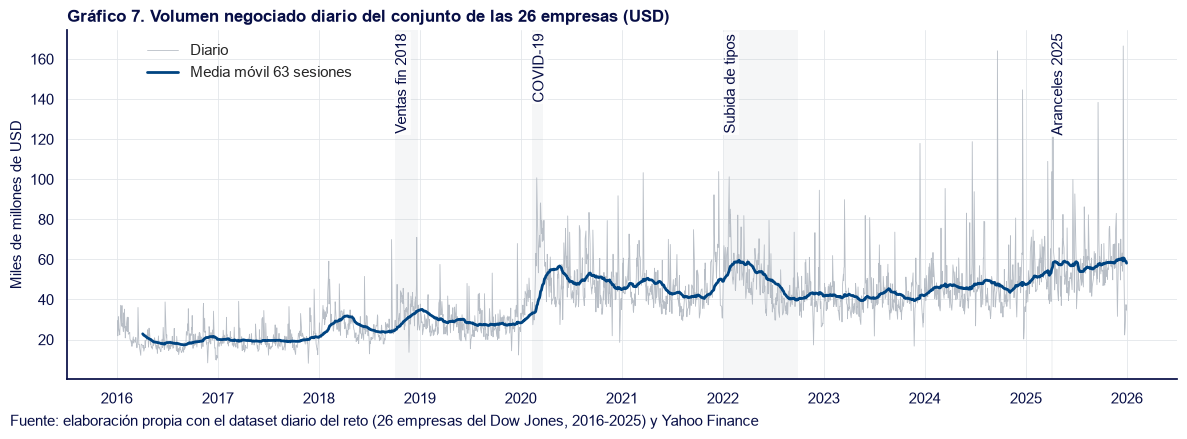

In [15]:
# Volumen en dólares (precio x acciones): no depende de los splits y es comparable entre empresas
dolares = precios * volumen
dolares_mercado = dolares.sum(axis=1, min_count=max(1, N - 6)) / 1e9

fig, ax = plt.subplots(figsize=(12, 4.3))
sombrear_episodios(ax, etiquetas=True)
ax.plot(dolares_mercado, color=GRIS, lw=0.6, label="Diario")
ax.plot(dolares_mercado.rolling(VENTANA_LARGA).mean(), color=AZUL, lw=2, label=f"Media móvil {VENTANA_LARGA} sesiones")
ax.set_ylabel("Miles de millones de USD")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper left", bbox_to_anchor=(0.06, 1))
ax.set_title(f"Gráfico 7. Volumen negociado diario del conjunto de las {N} empresas (USD)")
plt.tight_layout()
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g07_volumen_mercado")
plt.show()

Guardado: Graficos\descriptivo_g08_liquidez_por_empresa.png


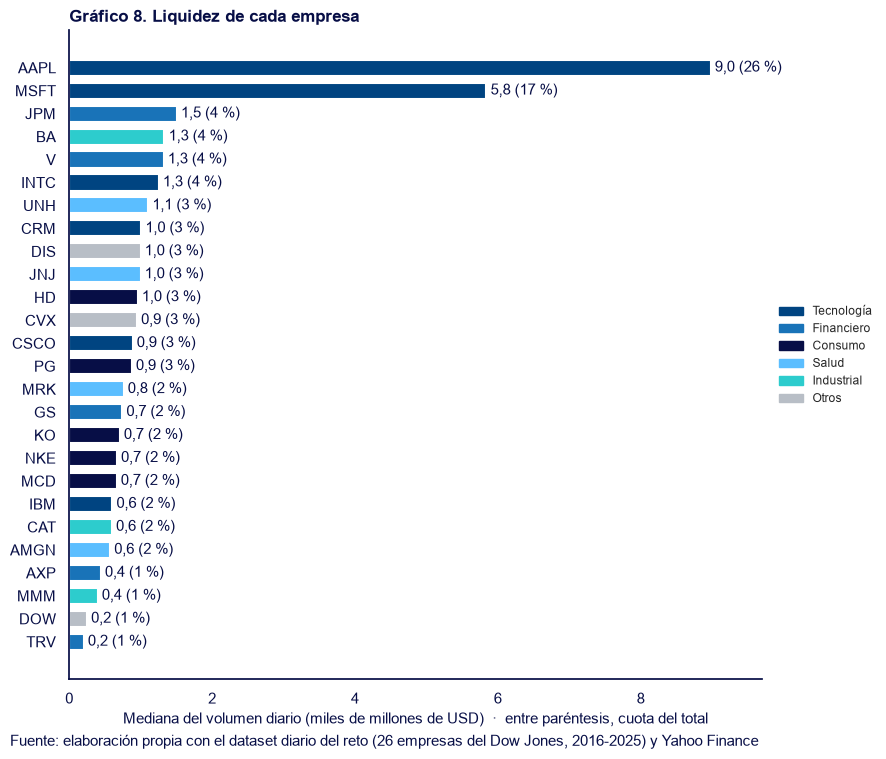

Las 5 empresas más líquidas concentran el 55 % del volumen
Correlación entre volumen del mercado y |rentabilidad| del mercado: 0,33


In [16]:
liquidez = (dolares.median() / 1e9).sort_values()
cuota = liquidez / liquidez.sum()

fig, ax = plt.subplots(figsize=(9, 7.5))
barras = ax.barh(liquidez.index, liquidez, color=[color(t) for t in liquidez.index], height=0.7,
                 edgecolor=FONDO, linewidth=1.5)
ax.bar_label(barras, labels=[f"{v:.1f} ({c:.0%})" for v, c in zip(liquidez, cuota)], padding=3,
             fontsize=11, color=TINTA_2)
ax.set_xlabel("Mediana del volumen diario (miles de millones de USD)  ·  entre paréntesis, cuota del total")
ax.grid(False)
ax.margins(x=0.08)
leyenda_sectores(ax)
ax.set_title("Gráfico 8. Liquidez de cada empresa")
plt.tight_layout()
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g08_liquidez_por_empresa")
plt.show()

imprimir(f"Las 5 empresas más líquidas concentran el {cuota.tail(5).sum():.0%} del volumen")
imprimir(f"Correlación entre volumen del mercado y |rentabilidad| del mercado: "
      f"{dolares_mercado.corr(rent_mercado.abs()):.2f}")

**Qué se observa:**
- El volumen negociado por las 26 empresas pasa de unos 20.000 millones de USD diarios en 2016-2017 a 40.000-60.000 desde 2020 (media móvil de 63 sesiones). Sube con los episodios de estrés (COVID-19, 2022, aranceles de 2025). Al inicio de la COVID-19, el único día por encima de 100.000 millones es el 28 de febrero de 2020 (el máximo de marzo es de 88.200), y en 2024-2025 hay picos de más de 125.000. La correlación entre el volumen y la rentabilidad absoluta del mercado es de 0,33: positiva pero moderada, porque también hay picos de volumen sin crisis.
- **Liquidez muy concentrada.** AAPL (9.000 millones diarios, el 26 % del total) y MSFT (5.800 millones, el 17 %) suman el 43 %; las cinco primeras, el 55 %. Aun así, las menos líquidas (TRV, con unos 200 millones diarios, y DOW, con unos 250; el 1 % del total cada una) siguen siendo muy líquidas, así que para una cartera normal la liquidez no es una restricción.

# 5. Rentabilidades diarias: medias, colas y días extremos

In [17]:
def estadisticos(r):
    r = r.dropna()
    return pd.Series({
        "media_anual": r.mean() * DIAS_ANIO,
        "volatilidad_anual": r.std() * np.sqrt(DIAS_ANIO),
        "asimetria": stats.skew(r),
        "curtosis_exceso": stats.kurtosis(r),          # 0 para una normal
        "peor_dia": r.min(), "fecha_peor": r.idxmin().date(),
        "mejor_dia": r.max(), "fecha_mejor": r.idxmax().date(),
        "pct_dias_positivos": (r > 0).mean(),
    })


tabla_r = rent_log.apply(estadisticos).T
tabla_r.loc["MERCADO"] = estadisticos(rent_log_mercado)
numericas = tabla_r.columns.drop(["fecha_peor", "fecha_mejor"])
tabla_r[numericas] = tabla_r[numericas].astype(float).round(4)
imprimir(tabla_r.loc[orden_sector + ["MERCADO"]].to_string())

         media_anual  volatilidad_anual  asimetria  curtosis_exceso  peor_dia  fecha_peor  mejor_dia fecha_mejor  pct_dias_positivos
symbol                                                                                                                              
AAPL          0,2341             0,2902    -0,0992           6,7371   -0,1395  2020-03-16     0,1426  2025-04-09              0,5368
CRM           0,1243             0,3496    -0,2591          13,1771   -0,2199  2024-05-30     0,2315  2020-08-26              0,5249
CSCO          0,1073             0,2523    -0,6942          12,0209   -0,1477  2022-05-19     0,1255  2020-03-13              0,5277
IBM           0,0826             0,2496    -0,4335          10,6363   -0,1375  2020-03-12     0,1219  2025-01-30              0,5328
INTC          0,0082             0,4043    -0,6021          16,2433   -0,3019  2024-08-02     0,2052  2025-09-18              0,5097
MSFT          0,2184             0,2676    -0,1620           7,9085  

Jarque-Bera = 51.146 (p-valor 0,0e+00) -> se rechaza la normalidad
Días con |r| > 3 desviaciones: 38 observados frente a 6,8 esperados con una normal


Guardado: Graficos\descriptivo_g09_distribucion_rentabilidades.png


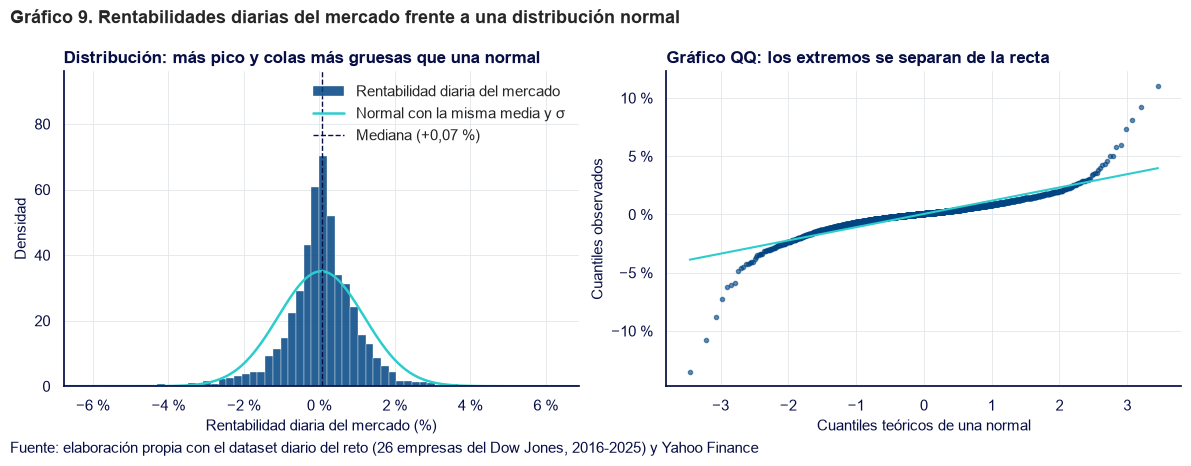

In [18]:
r = rent_log_mercado.dropna()
mu, sigma = r.mean(), r.std()
jb = stats.jarque_bera(r)
imprimir(f"Jarque-Bera = {jb.statistic:,.0f} (p-valor {jb.pvalue:.1e}) -> "
      f"{'se rechaza' if jb.pvalue < 0.05 else 'no se rechaza'} la normalidad")
imprimir(f"Días con |r| > 3 desviaciones: {(np.abs(r - mu) > 3 * sigma).sum()} observados "
      f"frente a {len(r) * 2 * stats.norm.sf(3):.1f} esperados con una normal")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.hist(r, bins=120, density=True, color=AZUL, alpha=0.85, edgecolor=FONDO, linewidth=0.3,
         label="Rentabilidad diaria del mercado")
x = np.linspace(r.min(), r.max(), 400)
ax1.plot(x, stats.norm.pdf(x, mu, sigma), color=NARANJA, lw=1.8, label="Normal con la misma media y σ")
ax1.set_xlim(mu - 6 * sigma, mu + 6 * sigma)
eje_pct(ax1, "x", 0)
ax1.set_ylabel("Densidad")
ax1.set_xlabel("Rentabilidad diaria del mercado (%)")
ax1.axvline(r.median(), color=TINTA, lw=1, ls="--", label=f"Mediana ({r.median():+.2%})")
ax1.set_ylim(0, ax1.get_ylim()[1] * 1.3)
ax1.legend(loc="upper right")
ax1.set_title("Distribución: más pico y colas más gruesas que una normal")

(teoricos, observados), _ = stats.probplot(r, dist="norm")
ax2.plot(teoricos, observados, "o", ms=3, color=AZUL, alpha=0.6)
ax2.plot(teoricos, mu + sigma * teoricos, color=NARANJA, lw=1.5)
ax2.set_xlabel("Cuantiles teóricos de una normal")
ax2.set_ylabel("Cuantiles observados")
eje_pct(ax2, "y", 0)
ax2.set_title("Gráfico QQ: los extremos se separan de la recta")
fig.suptitle("Gráfico 9. Rentabilidades diarias del mercado frente a una distribución normal", x=0.01, ha="left")
plt.tight_layout()
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g09_distribucion_rentabilidades")
plt.show()

In [19]:
extremos = pd.DataFrame({"rentabilidad": rent_mercado,
                         "empresas_en_negativo": (rent < 0).sum(axis=1) / rent.notna().sum(axis=1)})
imprimir("10 peores días del mercado:")
imprimir(extremos.nsmallest(10, "rentabilidad").assign(
    rentabilidad=lambda d: d["rentabilidad"].map("{:+.2%}".format),
    empresas_en_negativo=lambda d: d["empresas_en_negativo"].map("{:.0%}".format)).to_string())
imprimir("\n10 mejores días del mercado:")
imprimir(extremos.nlargest(10, "rentabilidad").assign(
    rentabilidad=lambda d: d["rentabilidad"].map("{:+.2%}".format),
    empresas_en_negativo=lambda d: d["empresas_en_negativo"].map("{:.0%}".format)).to_string())

10 peores días del mercado:
           rentabilidad empresas_en_negativo
date                                        
2020-03-16      -12,65 %                 100 %
2020-03-12      -10,18 %                 100 %
2020-03-09       -8,39 %                 100 %
2020-06-11       -6,98 %                 100 %
2025-04-04       -6,01 %                  96 %
2020-03-18       -5,87 %                  88 %
2020-03-11       -5,68 %                 100 %
2020-04-01       -4,73 %                 100 %
2020-02-27       -4,49 %                  96 %
2018-02-05       -4,40 %                 100 %

10 mejores días del mercado:
           rentabilidad empresas_en_negativo
date                                        
2020-03-24      +11,69 %                   0 %
2020-03-13       +9,65 %                   0 %
2025-04-09       +8,43 %                   0 %
2020-04-06       +7,65 %                   0 %
2020-03-26       +6,11 %                   4 %
2020-03-17       +5,96 %                  12 %
2020-03-10

**Qué se observa:**
- **Colas gruesas.** El índice tiene una curtosis en exceso de 21,0 (una normal tendría 0) y una asimetría de −0,34. El test de Jarque-Bera rechaza la normalidad, y hay 38 días con |r| > 3 desviaciones frente a los 6,8 que daría una normal (5,6 veces más). En el gráfico 9 se ve más pico central y colas más gruesas, y el QQ se separa de la recta a partir de ±2 desviaciones.
- **Días extremos concentrados en 2020.** El peor día es el 16/03/2020 (−12,65 %) y el mejor el 24/03/2020 (+11,69 %). 8 de los 10 peores y 8 de los 10 mejores días son de 2020, casi todos de marzo: las subidas más fuertes llegan en plena crisis.
- **Diversificación en los días extremos.** En 7 de los 10 peores días cae el 100 % de las empresas (en los otros tres, entre el 88 % y el 96 %), y en 8 de los 10 mejores días no cae ninguna. Cuando el mercado se mueve mucho, todas se mueven en la misma dirección.
- **Por empresa.** La asimetría es negativa en la mayoría, sobre todo en TRV (−1,92) y UNH (−1,80). La curtosis en exceso va de 4,9 (CAT) a más de 30 (MCD y TRV): unos pocos días explican gran parte del riesgo de esas empresas.

# 6. Volatilidad: cuánto riesgo hay y cómo cambia en el tiempo

Guardado: Graficos\descriptivo_g10_volatilidad_por_empresa.png


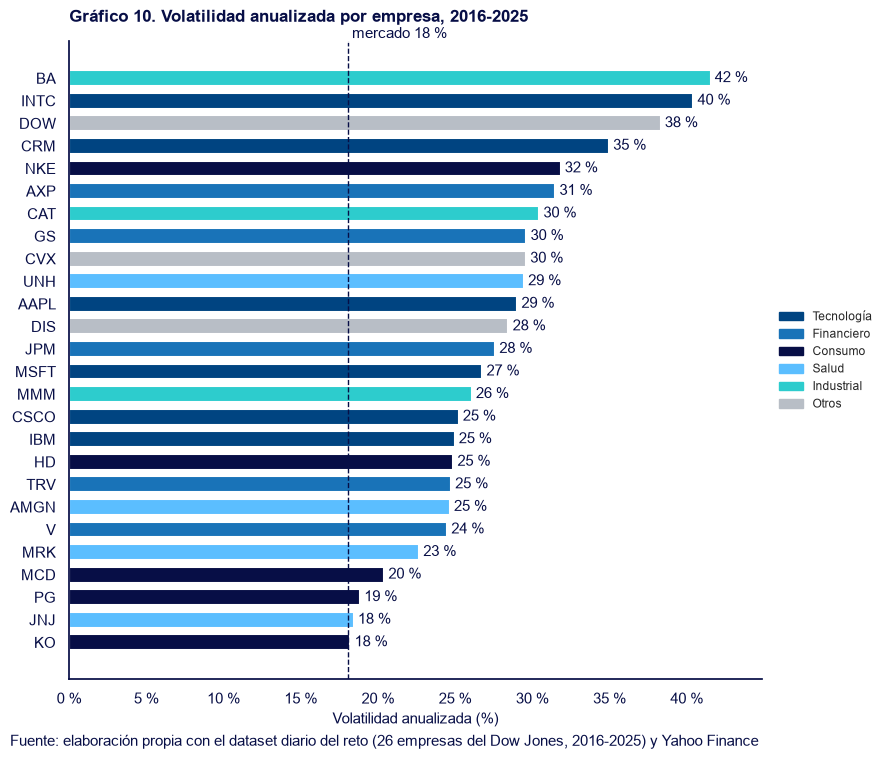

Volatilidad media de las empresas 27,8 % frente a la del mercado 18,1 %: la diversificación elimina un 35 % del riesgo medio


In [20]:
vol_empresas = (rent_log.std() * np.sqrt(DIAS_ANIO)).sort_values()
vol_mercado = rent_log_mercado.std() * np.sqrt(DIAS_ANIO)

fig, ax = plt.subplots(figsize=(9, 7.5))
barras = ax.barh(vol_empresas.index, vol_empresas, color=[color(t) for t in vol_empresas.index],
                 height=0.7, edgecolor=FONDO, linewidth=1.5)
ax.bar_label(barras, labels=[f"{v:.0%}" for v in vol_empresas], padding=3, fontsize=11, color=TINTA_2)
ax.axvline(vol_mercado, color=TINTA_2, lw=1, ls="--")
ax.text(vol_mercado, 1.0, f" mercado {vol_mercado:.0%}", transform=ax.get_xaxis_transform(),
        fontsize=11, color=TINTA_2, va="bottom")
eje_pct(ax, "x")
ax.grid(False)
ax.set_xlabel("Volatilidad anualizada (%)")
ax.margins(x=0.08)
leyenda_sectores(ax)
ax.set_title("Gráfico 10. Volatilidad anualizada por empresa, 2016-2025", pad=14)
plt.tight_layout()
for t in ax.texts:
    t.set_bbox(dict(facecolor=FONDO, edgecolor="none", alpha=0.85, pad=1))
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g10_volatilidad_por_empresa")
plt.show()

imprimir(f"Volatilidad media de las empresas {vol_empresas.mean():.1%} frente a la del mercado {vol_mercado:.1%}: "
      f"la diversificación elimina un {1 - vol_mercado / vol_empresas.mean():.0%} del riesgo medio")

Guardado: Graficos\descriptivo_g11_volatilidad_movil.png


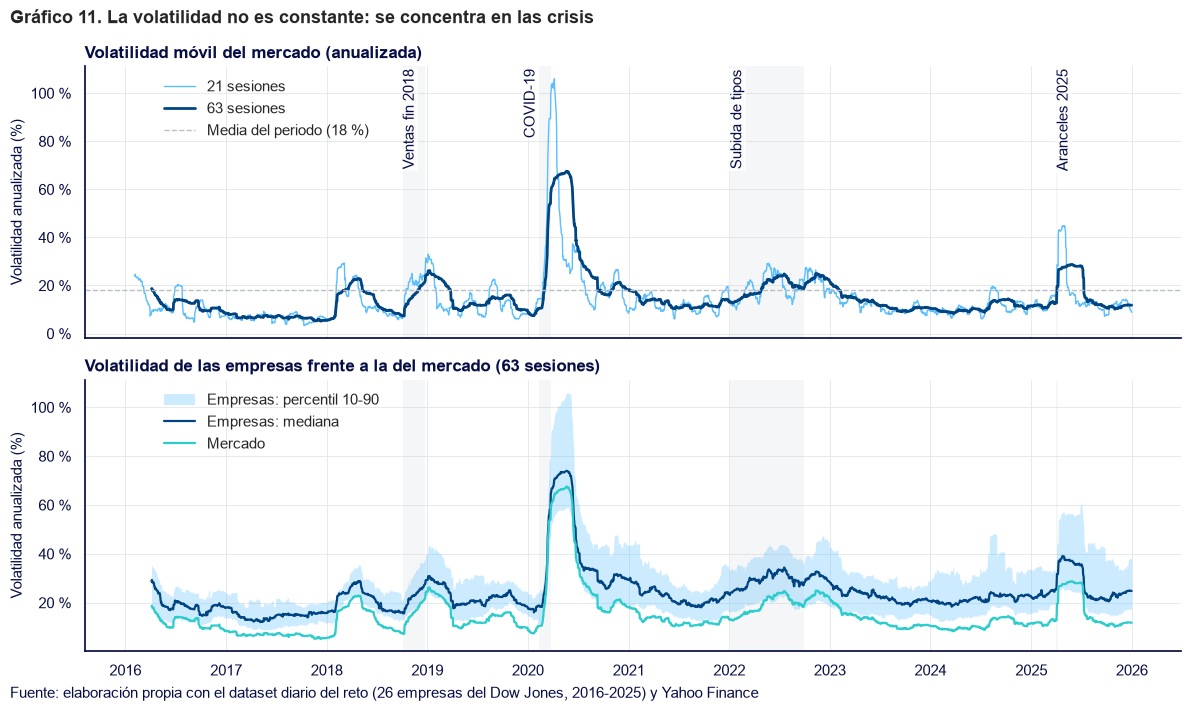

Volatilidad del mercado por año: {2016: 13,3, 2017: 6,6, 2018: 17,9, 2019: 12,6, 2020: 37,6, 2021: 12,7, 2022: 20,7, 2023: 11,8, 2024: 11,2, 2025: 17,3}


In [21]:
vol_corta = rent_log_mercado.rolling(VENTANA_CORTA).std() * np.sqrt(DIAS_ANIO)
vol_larga = rent_log_mercado.rolling(VENTANA_LARGA).std() * np.sqrt(DIAS_ANIO)
vol_movil_empresas = rent_log.rolling(VENTANA_LARGA, min_periods=VENTANA_LARGA).std() * np.sqrt(DIAS_ANIO)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
sombrear_episodios(ax1, etiquetas=True, izquierda=("COVID-19",))
ax1.plot(vol_corta, color=BBVA["cielo"], lw=1, label=f"{VENTANA_CORTA} sesiones")
ax1.plot(vol_larga, color=AZUL, lw=2, label=f"{VENTANA_LARGA} sesiones")
ax1.axhline(vol_mercado, color=GRIS, lw=1, ls="--", label=f"Media del periodo ({vol_mercado:.0%})")
eje_pct(ax1)
ax1.set_ylabel("Volatilidad anualizada (%)")
ax1.legend(loc="upper left", bbox_to_anchor=(0.06, 1))
ax1.set_title("Volatilidad móvil del mercado (anualizada)")

sombrear_episodios(ax2)
ax2.fill_between(vol_movil_empresas.index, vol_movil_empresas.quantile(0.1, axis=1),
                 vol_movil_empresas.quantile(0.9, axis=1), color=BBVA["cielo"], alpha=0.3, lw=0,
                 label="Empresas: percentil 10-90")
ax2.plot(vol_movil_empresas.median(axis=1), color=AZUL, lw=1.6, label="Empresas: mediana")
ax2.plot(vol_larga, color=NARANJA, lw=1.6, label="Mercado")
eje_pct(ax2)
ax2.set_ylabel("Volatilidad anualizada (%)")
ax2.legend(loc="upper left", bbox_to_anchor=(0.06, 1))
ax2.set_title(f"Volatilidad de las empresas frente a la del mercado ({VENTANA_LARGA} sesiones)")
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Gráfico 11. La volatilidad no es constante: se concentra en las crisis", x=0.01, ha="left")
plt.tight_layout()
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g11_volatilidad_movil")
plt.show()

vol_por_anio = rent_log_mercado.groupby(rent_log_mercado.index.year).std() * np.sqrt(DIAS_ANIO)
imprimir("Volatilidad del mercado por año:", (vol_por_anio * 100).round(1).to_dict())

**Qué se observa:**
- **Efecto diversificación.** La volatilidad media de las empresas es del 27,8 % y la del mercado, del 18,1 %: la diversificación elimina un 35 % del riesgo medio. Ninguna empresa es menos volátil que el mercado; solo KO (18,1 %) y JNJ (18,4 %) lo igualan. En el otro extremo están BA (42 %), INTC (40 %) y DOW (38 %).
- **Regímenes.** La volatilidad del mercado cambia mucho según el año: de un 6,6 % en 2017 a un 37,6 % en 2020, con 2022 en el 20,7 % y 2025 en el 17,3 %. En marzo de 2020 la volatilidad a 63 sesiones llegó a casi el 70 % y la de 21 sesiones superó el 100 %. Hay largos periodos tranquilos (2016-2017, 2023-2024) y picos muy cortos y muy altos.
- **Convergencia en las crisis.** En 2017 la volatilidad del mercado (en torno al 7 %) era aproximadamente la mitad de la mediana de las empresas; en el pico de 2020 la mediana (≈ 74 %) y el mercado (≈ 68 %) casi se juntan. La diversificación ayuda menos justo cuando más falta hace.

# 7. Riesgo frente a rentabilidad: qué empresas compensan su riesgo

In [22]:
# Tasa libre de riesgo: media de la letra del Tesoro a 13 semanas (^IRX, en %) o el valor por defecto
yahoo_irx = descargar_yahoo(["^IRX"], ["Close"])
if yahoo_irx is not None and yahoo_irx["Close"]["^IRX"].notna().any():
    TASA_LIBRE = yahoo_irx["Close"]["^IRX"].mean() / 100
    imprimir(f"Tasa libre de riesgo (media de ^IRX 2016-2025): {TASA_LIBRE:.2%}")
else:
    TASA_LIBRE = TASA_LIBRE_DEFECTO
    imprimir(f"Tasa libre de riesgo por defecto: {TASA_LIBRE:.2%}")


def ratios(r_simple):
    r_simple = r_simple.dropna()
    media = r_simple.mean() * DIAS_ANIO
    vol = r_simple.std() * np.sqrt(DIAS_ANIO)
    bajista = np.sqrt((np.minimum(r_simple, 0) ** 2).mean()) * np.sqrt(DIAS_ANIO)
    return pd.Series({"rentabilidad_media": media, "volatilidad": vol,
                      "sharpe": (media - TASA_LIBRE) / vol, "sortino": (media - TASA_LIBRE) / bajista})


riesgo = rent.apply(ratios).T
riesgo["cagr"] = cagr_empresas
riesgo.loc["MERCADO"] = ratios(rent_mercado)
riesgo.loc["MERCADO", "cagr"] = cagr_mercado
imprimir(riesgo.sort_values("sharpe", ascending=False).round(3).to_string())

Tasa libre de riesgo (media de ^IRX 2016-2025): 2,16 %
         rentabilidad_media  volatilidad  sharpe  sortino   cagr
symbol                                                          
AAPL                  0,276        0,290   0,877    1,294  0,263
MSFT                  0,254        0,268   0,869    1,282  0,244
CAT                   0,260        0,304   0,784    1,148  0,238
V                     0,184        0,245   0,662    0,958  0,166
JPM                   0,201        0,276   0,649    0,957  0,176
MERCADO               0,135        0,180   0,628    0,889  0,125
AXP                   0,220        0,317   0,626    0,946  0,185
GS                    0,205        0,296   0,617    0,906  0,174
CRM                   0,185        0,350   0,469    0,677  0,132
CSCO                  0,139        0,251   0,468    0,656  0,113
MCD                   0,117        0,204   0,466    0,676  0,100
TRV                   0,128        0,244   0,434    0,593  0,102
UNH                   0,147        

In [23]:
puntos = riesgo.drop("MERCADO")
mercado = riesgo.loc["MERCADO"]
POSICION = {"TRV": "top left", "HD": "middle right", "MRK": "middle left",   # etiquetas que se pisaban
            "AMGN": "bottom right", "KO": "bottom right"}

fig = go.Figure()
for sector, col in COLOR_SECTOR.items():
    grupo = puntos[[SECTOR[t] == sector for t in puntos.index]]
    if grupo.empty:
        continue
    fig.add_trace(go.Scatter(
        x=100 * grupo["volatilidad"], y=100 * grupo["rentabilidad_media"], mode="markers+text", name=sector,
        text=list(grupo.index), textposition=[POSICION.get(t, "top right") for t in grupo.index],
        textfont=dict(size=12, color=TINTA_2),
        marker=dict(size=11, color=col, opacity=0.8, line=dict(width=1.5, color=FONDO)),
        customdata=[[NOMBRE[t], s] for t, s in zip(grupo.index, grupo["sharpe"])],
        hovertemplate="<b>%{text}</b> · %{customdata[0]}<br>Volatilidad: %{x:.1f} %<br>"
                      "Rentabilidad media: %{y:.1f} %<br>Sharpe: %{customdata[1]:.2f}<extra></extra>"))
fig.add_trace(go.Scatter(
    x=[100 * mercado["volatilidad"]], y=[100 * mercado["rentabilidad_media"]], mode="markers+text",
    text=["<b>MERCADO</b>"], textposition="top left", textfont=dict(size=12, color=TINTA), showlegend=False,
    marker=dict(size=16, symbol="diamond", color=TINTA), customdata=[mercado["sharpe"]],
    hovertemplate="<b>Mercado</b> (índice equiponderado)<br>Volatilidad: %{x:.1f} %<br>"
                  "Rentabilidad media: %{y:.1f} %<br>Sharpe: %{customdata:.2f}<extra></extra>"))

# Línea con el Sharpe del mercado: por encima, más rentabilidad por unidad de riesgo que el mercado
x = np.linspace(0, puntos["volatilidad"].max() * 1.05, 50)
fig.add_trace(go.Scatter(x=100 * x, y=100 * (TASA_LIBRE + mercado["sharpe"] * x), mode="lines", showlegend=False,
                         line=dict(color=GRIS, width=1, dash="dash"), hoverinfo="skip"))
fig.add_annotation(x=100 * x[-1], y=100 * (TASA_LIBRE + mercado["sharpe"] * x[-1]), text="Sharpe del mercado",
                   xanchor="left", showarrow=False, font=dict(size=12, color=TINTA_2))
fig.add_hline(y=0, line=dict(color=TINTA_2, width=0.8))
fig.update_layout(
    title="Gráfico 12. Rentabilidad frente a riesgo por empresa (2016-2025)",
    xaxis=dict(title="Volatilidad anualizada (%)", ticksuffix=" %", range=[0, 100 * x[-1] * 1.12]),
    yaxis=dict(title="Rentabilidad media anual (media diaria x 252)", ticksuffix=" %"),
    legend=dict(title="Sector", y=-0.14))
guardar_interactivo(fig, "descriptivo_g12_riesgo_frente_a_rentabilidad", ancho=1100, alto=780, margen=175)

Guardado: Graficos\descriptivo_g12_riesgo_frente_a_rentabilidad.png


**Qué se observa:**
- El mercado tiene una rentabilidad media del 13,5 % con una volatilidad del 18,0 % (Sharpe 0,63, con una tasa libre de riesgo media del 2,16 %). Por encima de la línea del mercado están AAPL (Sharpe 0,88), MSFT (0,87), CAT (0,78), V (0,66) y JPM (0,65); AXP (0,63) y GS (0,62) están sobre la línea. Todas las demás quedan por debajo, y las peores son DOW (−0,16), NKE (0,10), DIS (0,10), MMM (0,15) e INTC (0,17).
- **Más riesgo no es más rentabilidad.** BA e INTC tienen las mayores volatilidades (42 % y 40 %) con rentabilidades de solo el 13 % y el 9 %. Las defensivas JNJ, PG y KO igualan el riesgo del mercado (18-19 %) pero con rentabilidades del 7-9 % (Sharpe 0,25-0,37); MCD es la mejor de ellas (Sharpe 0,47).
- **Sortino frente a Sharpe.** El Sortino es entre 1,4 y 1,5 veces el Sharpe en todas las empresas, así que ninguna destaca por tener una volatilidad que venga sobre todo de subidas. Conviene usarlo solo para comparar entre empresas: su numerador resta la tasa libre de riesgo, pero la desviación a la baja se mide respecto a 0, no respecto a la tasa libre.
- Estas rentabilidades son medias aritméticas anualizadas (por eso el mercado marca el 13,5 % y no el 12,5 % del CAGR) y no incluyen dividendos.

# 8. Drawdowns: cuánto se puede llegar a perder y cuánto se tarda en recuperar

In [24]:
def drawdown(nivel):
    nivel = nivel.dropna()
    return nivel / nivel.cummax() - 1


def episodios_drawdown(nivel, umbral=-0.10):
    """Caídas desde un máximo de más del umbral: fecha del máximo, del mínimo y de la recuperación."""
    dd = drawdown(nivel)
    grupo = (dd == 0).cumsum()
    filas = []
    for _, tramo in dd.groupby(grupo):
        if tramo.min() > umbral:
            continue
        posicion = dd.index.get_loc(tramo.index[-1])
        recuperacion = dd.index[posicion + 1] if posicion + 1 < len(dd) else pd.NaT
        filas.append({"maximo": tramo.index[0].date(), "minimo": tramo.idxmin().date(),
                      "recuperacion": recuperacion.date() if pd.notna(recuperacion) else "sin recuperar",
                      "caida": tramo.min(), "sesiones_hasta_minimo": dd.index.get_loc(tramo.idxmin()) - dd.index.get_loc(tramo.index[0]),
                      "sesiones_total": len(tramo)})
    return pd.DataFrame(filas).sort_values("caida")


dd_mercado = drawdown(indice_ew)
imprimir("Caídas del mercado de más del 10 %:")
imprimir(episodios_drawdown(indice_ew).assign(caida=lambda d: d["caida"].map("{:.1%}".format)).to_string(index=False))

relleno = "rgba({}, {}, {}, 0.35)".format(*(int(ROJO[i:i + 2], 16) for i in (1, 3, 5)))
fig = go.Figure(go.Scatter(
    x=dd_mercado.index, y=100 * dd_mercado, mode="lines", fill="tozeroy", fillcolor=relleno,
    line=dict(color=ROJO, width=1.2),
    hovertemplate="%{x|%d/%m/%Y}<br>Caída desde el máximo previo: %{y:.1f} %<extra></extra>"))
fig.add_annotation(x=dd_mercado.idxmin().strftime("%Y-%m-%d"), y=100 * dd_mercado.min(), text=texto_es(f"máximo {dd_mercado.min():.1%}"),
                   xanchor="left", xshift=8, showarrow=False, font=dict(size=12, color=TINTA_2))
fig.update_layout(title="Gráfico 13. Drawdown del índice equiponderado", showlegend=False,
                  yaxis=dict(title="Caída desde el máximo previo (%)", ticksuffix=" %"))
fechas_plotly(fig)
guardar_interactivo(fig, "descriptivo_g13_drawdown_mercado", alto=450)

Caídas del mercado de más del 10 %:
    maximo     minimo recuperacion  caida  sesiones_hasta_minimo  sesiones_total
2020-02-12 2020-03-23   2020-09-02 -35,7 %                     27             141
2022-01-04 2022-09-30   2023-11-30 -22,7 %                    186             479
2025-02-19 2025-04-08   2025-07-10 -16,6 %                     34              97
2018-10-03 2018-12-24   2019-03-18 -16,5 %                     56             112
2018-01-26 2018-02-08   2018-08-07 -10,6 %                      9             133


Guardado: Graficos\descriptivo_g13_drawdown_mercado.png


Guardado: Graficos\descriptivo_g14_max_drawdown_por_empresa.png


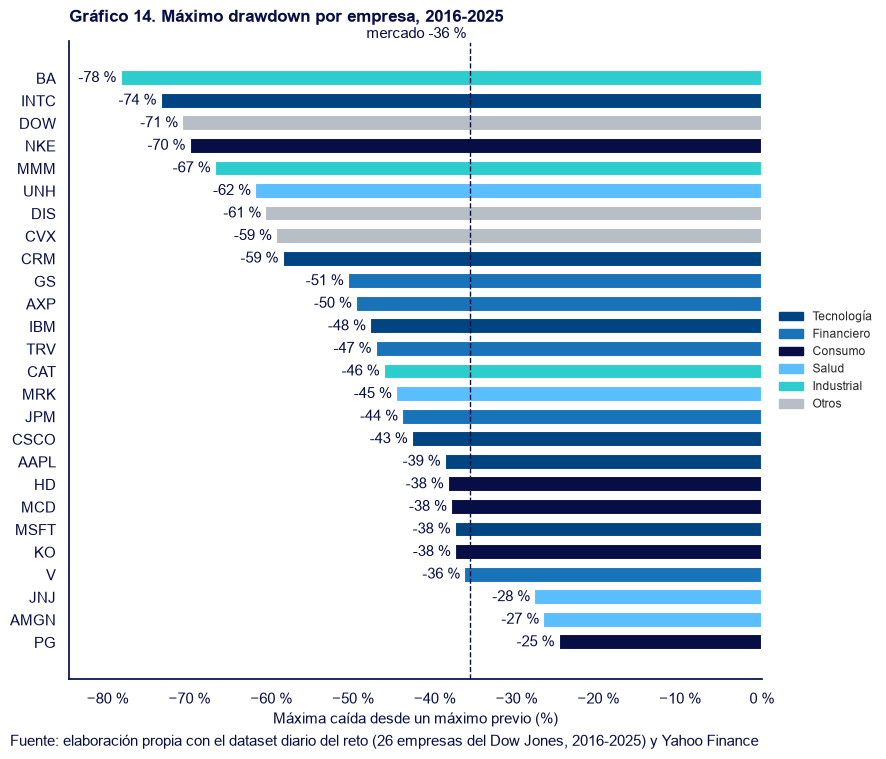

Empresas que a final de 2025 siguen más de un 20 % por debajo de su máximo:
        max_drawdown fecha_minimo  drawdown_final
symbol                                           
PG            -0,249   2018-05-02          -0,203
HD            -0,384   2020-03-20          -0,202
MRK           -0,447   2025-05-14          -0,208
CRM           -0,586   2022-12-16          -0,280
DIS           -0,607   2023-10-04          -0,437
UNH           -0,620   2025-08-01          -0,472
MMM           -0,669   2023-10-23          -0,260
NKE           -0,700   2025-04-08          -0,641
DOW           -0,709   2025-10-10          -0,670
INTC          -0,735   2025-04-08          -0,461
BA            -0,784   2020-03-20          -0,507


In [25]:
dd_empresas = pd.DataFrame({
    "max_drawdown": precios.apply(lambda s: drawdown(s).min()),
    "fecha_minimo": precios.apply(lambda s: drawdown(s).idxmin().date()),
    "drawdown_final": precios.apply(lambda s: drawdown(s).iloc[-1]),
}).sort_values("max_drawdown", ascending=False)

fig, ax = plt.subplots(figsize=(9, 7.5))
barras = ax.barh(dd_empresas.index, dd_empresas["max_drawdown"],
                 color=[color(t) for t in dd_empresas.index], height=0.7, edgecolor=FONDO, linewidth=1.5)
ax.bar_label(barras, labels=[f"{v:.0%}" for v in dd_empresas["max_drawdown"]], padding=3, fontsize=11,
             color=TINTA_2)
ax.axvline(dd_mercado.min(), color=TINTA_2, lw=1, ls="--")
ax.text(dd_mercado.min(), 1.0, f"mercado {dd_mercado.min():.0%} ", transform=ax.get_xaxis_transform(),
        fontsize=11, color=TINTA_2, va="bottom", ha="right")
eje_pct(ax, "x")
ax.grid(False)
ax.set_xlabel("Máxima caída desde un máximo previo (%)")
ax.margins(x=0.08)
leyenda_sectores(ax)
ax.set_title("Gráfico 14. Máximo drawdown por empresa, 2016-2025", pad=14)
plt.tight_layout()
for t in ax.texts:
    t.set_bbox(dict(facecolor=FONDO, edgecolor="none", alpha=0.85, pad=1))
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g14_max_drawdown_por_empresa")
plt.show()

imprimir("Empresas que a final de 2025 siguen más de un 20 % por debajo de su máximo:")
imprimir(dd_empresas[dd_empresas["drawdown_final"] < -0.2].round(3).to_string())

**Qué se observa:**
- **El mercado.** La mayor caída fue la del COVID-19: −35,7 % entre el 12/02/2020 y el 23/03/2020 (27 sesiones hasta el mínimo), con recuperación del máximo previo el 02/09/2020 (141 sesiones en total). La caída de 2022 fue menos profunda (−22,7 %) pero mucho más lenta: 186 sesiones hasta el mínimo y 479 hasta recuperar el máximo (30/11/2023). Las otras tres caídas de más del 10 % son las de 2025 (−16,6 %, 97 sesiones), finales de 2018 (−16,5 %, 112) y febrero de 2018 (−10,6 %, 133).
- **Las empresas.** Los peores máximos drawdowns son los de BA (−78 %), INTC (−74 %), DOW (−71 %) y NKE (−70 %). Solo PG (−25 %), AMGN (−27 %) y JNJ (−28 %) caen menos que el mercado (−36 %); V lo iguala.
- **Sin recuperar.** A finales de 2025, 11 empresas siguen más de un 20 % por debajo de su máximo: DOW (−67 %), NKE (−64 %), BA (−51 %), UNH (−47 %), INTC (−46 %) y DIS (−44 %) son las peores.
- **Volatilidad y drawdown no ordenan igual.** UNH tiene una volatilidad media (29 %) pero cayó un 62 % y sigue un 47 % por debajo de su máximo; MMM, con un 26 % de volatilidad, llegó a −67 %. HD, con una volatilidad parecida (25 %), tocó fondo en −38 %.

# 9. Correlaciones: cuánto se mueven juntas y si cambia en las crisis

Guardado: Graficos\descriptivo_g15_matriz_correlaciones.png


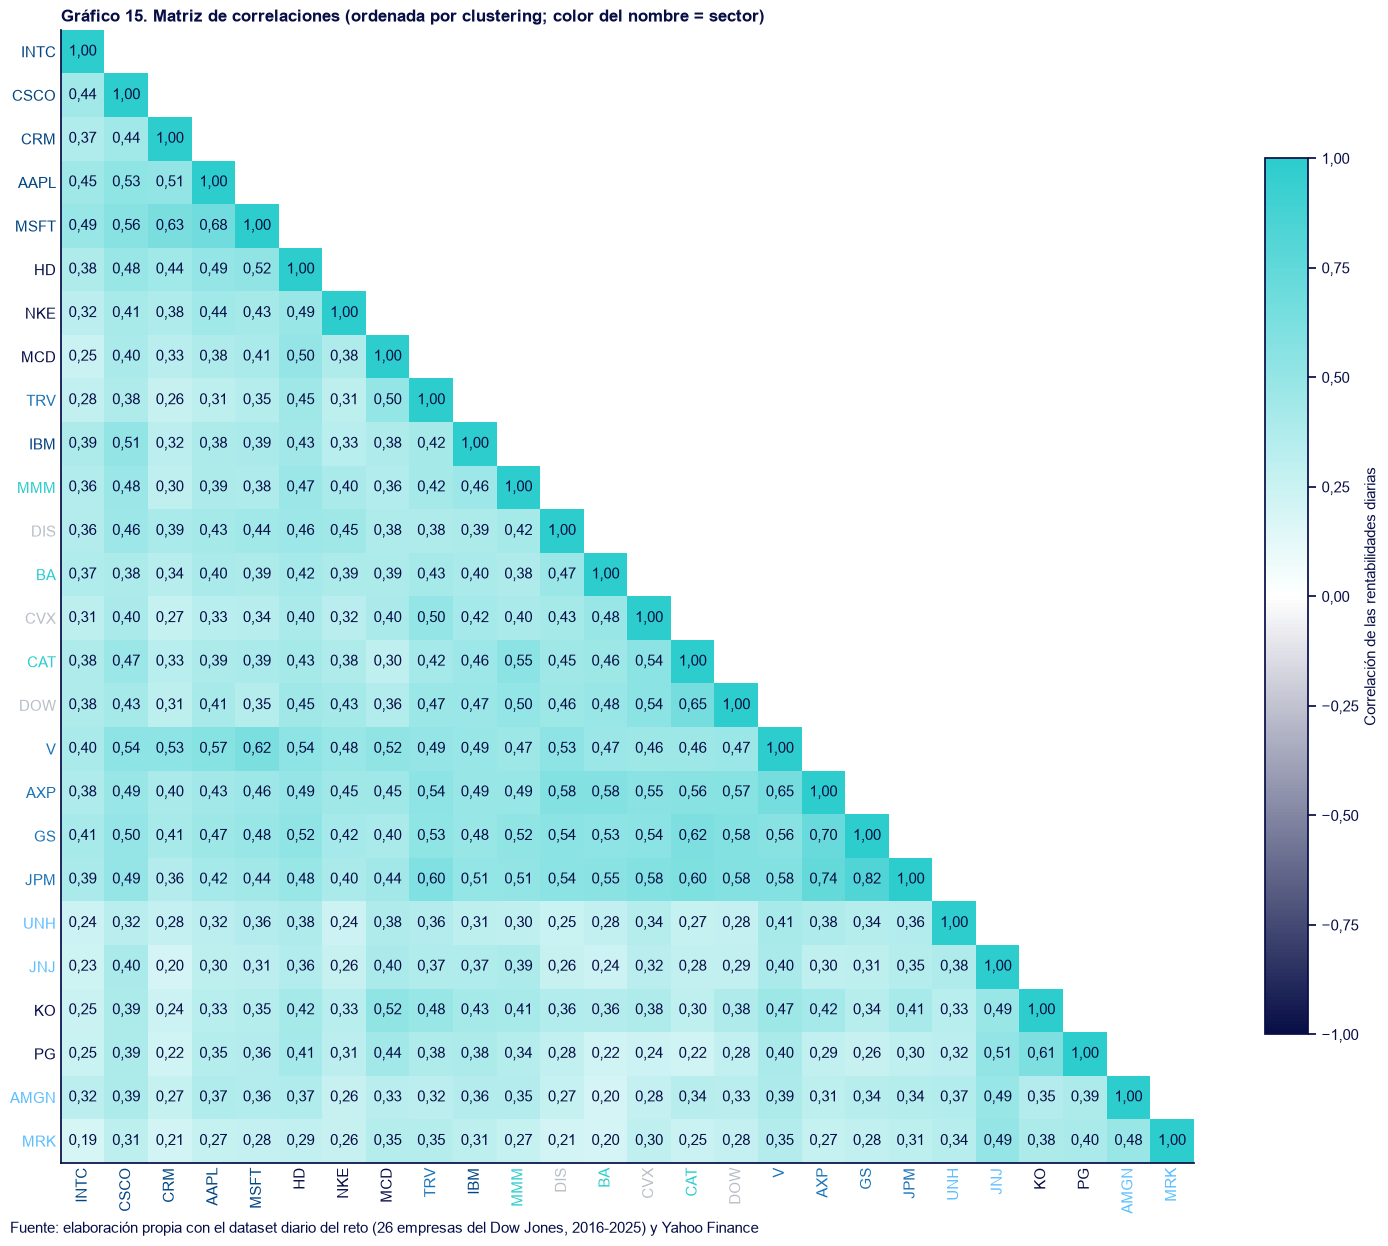

Correlación media entre empresas: 0,40
Pares más correlacionados: {('GS', 'JPM'): 0,82, ('AXP', 'JPM'): 0,74, ('AXP', 'GS'): 0,7, ('AAPL', 'MSFT'): 0,68, ('CAT', 'DOW'): 0,65}
Pares menos correlacionados: {('INTC', 'MRK'): 0,19, ('BA', 'MRK'): 0,2, ('CRM', 'JNJ'): 0,2, ('AMGN', 'BA'): 0,2, ('DIS', 'MRK'): 0,21}


In [26]:
correlacion = rent_log.corr()

# Orden por clustering jerárquico: las empresas que se mueven parecido quedan juntas
distancia = np.sqrt(0.5 * (1 - correlacion.clip(-1, 1).to_numpy()))
np.fill_diagonal(distancia, 0)
orden_cluster = correlacion.index[leaves_list(linkage(squareform(distancia, checks=False), "average"))]
matriz = correlacion.loc[orden_cluster, orden_cluster]

mascara = np.triu(np.ones(matriz.shape, dtype=bool), k=1)      # matriz simétrica: se oculta el triángulo superior
fig, ax = plt.subplots(figsize=(15, 13))
imagen = ax.imshow(np.ma.masked_array(matriz.values, mascara), cmap=DIVERGENTE, vmin=-1, vmax=1)
for i in range(len(matriz)):
    for j in range(i + 1):
        ax.text(j, i, f"{matriz.values[i, j]:.2f}", ha="center", va="center", fontsize=11, color=TINTA)
ax.set_xticks(range(len(matriz)), matriz.columns, rotation=90)
ax.set_yticks(range(len(matriz)), matriz.index)
for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
    etiqueta.set_color(color(etiqueta.get_text()))
ax.grid(False)
ax.tick_params(length=0)
fig.colorbar(imagen, ax=ax, shrink=0.7, label="Correlación de las rentabilidades diarias")
ax.set_title("Gráfico 15. Matriz de correlaciones (ordenada por clustering; color del nombre = sector)")
plt.tight_layout()
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g15_matriz_correlaciones")
plt.show()

fuera_diagonal = correlacion.where(~np.eye(len(correlacion), dtype=bool))
imprimir(f"Correlación media entre empresas: {np.nanmean(fuera_diagonal.values):.2f}")
pares = fuera_diagonal.stack()
pares = pares[pares.index.get_level_values(0) < pares.index.get_level_values(1)]
imprimir("Pares más correlacionados:", pares.nlargest(5).round(2).to_dict())
imprimir("Pares menos correlacionados:", pares.nsmallest(5).round(2).to_dict())

In [27]:
# Correlación media dentro de cada sector frente a la correlación con el resto
filas = []
for sector in COLOR_SECTOR:
    dentro = [t for t in empresas if SECTOR[t] == sector]
    if not dentro:
        continue
    fuera = [t for t in empresas if SECTOR[t] != sector]
    intra = fuera_diagonal.loc[dentro, dentro].stack().mean() if len(dentro) > 1 else np.nan
    filas.append({"sector": sector, "empresas": len(dentro), "corr_dentro_sector": intra,
                  "corr_con_otros_sectores": correlacion.loc[dentro, fuera].stack().mean()})
imprimir(pd.DataFrame(filas).round(2).to_string(index=False))

    sector  empresas  corr_dentro_sector  corr_con_otros_sectores
Tecnología         6                0,47                     0,38
Financiero         5                0,62                     0,44
   Consumo         5                0,44                     0,38
     Salud         4                0,43                     0,32
Industrial         3                0,46                     0,40
     Otros         3                0,48                     0,41


In [28]:
def correlacion_media_movil(r, ventana):
    """Media de las correlaciones entre pares en cada ventana (solo empresas con la ventana completa)."""
    valores, datos = {}, r.values
    for fin in range(ventana, len(r) + 1):
        bloque = datos[fin - ventana:fin]
        completas = ~np.isnan(bloque).any(axis=0)
        c = np.corrcoef(bloque[:, completas], rowvar=False)
        n = c.shape[0]
        valores[r.index[fin - 1]] = (c.sum() - n) / (n * (n - 1))
    return pd.Series(valores)


corr_movil = correlacion_media_movil(rent_log.iloc[1:], VENTANA_LARGA)

fig = go.Figure()
for nombre, (ini, fin) in EPISODIOS.items():     # episodios de caída sombreados, como en el resto de gráficos
    fig.add_vrect(x0=ini, x1=fin, fillcolor=GRIS, opacity=0.13, line_width=0, layer="below")
    izquierda = nombre == "COVID-19"              # su etiqueta taparía el pico si fuera a la derecha
    fig.add_annotation(x=(pd.Timestamp(ini) - pd.Timedelta(days=6 if izquierda else 0)).strftime("%Y-%m-%d"), y=1,
                       yref="paper",
                       text=nombre, textangle=-90, xanchor="right" if izquierda else "left", yanchor="top",
                       showarrow=False, bgcolor="rgba(255, 255, 255, 0.7)", font=dict(size=12, color=TINTA_2))
fig.add_trace(go.Scatter(x=corr_movil.index, y=corr_movil, mode="lines", line=dict(color=AZUL, width=1.8),
                         hovertemplate="%{x|%d/%m/%Y}<br>Correlación media: %{y:.2f}<extra></extra>"))
fig.add_hline(y=corr_movil.mean(), line=dict(color=GRIS, width=1, dash="dash"))
fig.add_annotation(x="2023-09-15", y=corr_movil.mean(), text=texto_es(f"media {corr_movil.mean():.2f}"),
                   xanchor="left", yanchor="bottom", showarrow=False, font=dict(size=12, color=TINTA_2))
fig.update_layout(title=f"Gráfico 16. Correlación media entre empresas, ventana móvil de {VENTANA_LARGA} sesiones",
                  showlegend=False, yaxis=dict(title="Correlación media entre pares", range=[0, 1]))
fechas_plotly(fig)
guardar_interactivo(fig, "descriptivo_g16_correlacion_movil", alto=480)

imprimir(f"Correlación entre la correlación media y la volatilidad del mercado: {corr_movil.corr(vol_larga):.2f}")

Guardado: Graficos\descriptivo_g16_correlacion_movil.png


Correlación entre la correlación media y la volatilidad del mercado: 0,82


**Qué se observa:**
- **Correlación media entre empresas: 0,40.** Los pares más correlacionados son GS-JPM (0,82), AXP-JPM (0,74), AXP-GS (0,70), AAPL-MSFT (0,68) y CAT-DOW (0,65). Los menos, INTC-MRK (0,19), BA-MRK (0,20), CRM-JNJ (0,20) y AMGN-BA (0,20).
- **El sector importa.** En los seis grupos la correlación dentro del grupo es mayor que con el resto: financiero 0,62 frente a 0,44; tecnología 0,47 frente a 0,38; industrial 0,46 frente a 0,40; consumo 0,44 frente a 0,38; salud 0,43 frente a 0,32; otros 0,48 frente a 0,41 (esta última fila agrupa energía, comunicación y materiales, así que no es un sector real y no debe interpretarse). Salud es el sector que menos se correlaciona con el resto (0,32). En el gráfico 15 las financieras forman un bloque claro, y las defensivas (UNH, JNJ, AMGN y MRK, de salud, y KO y PG, de consumo básico) forman otro, poco correlacionado con el resto: son los mejores candidatos para diversificar.
- **Las crisis suben la correlación (gráfico 16).** La correlación media en ventanas de 63 sesiones baja a 0,08 en la calma de principios de 2018 y se mueve en 0,15-0,25 en 2017 y 2024-2025, pero sube hasta 0,82 en marzo de 2020 (más del doble de la media del periodo) y a 0,62, 0,57 y 0,52 en los episodios de 2018, 2022 y 2025. El coeficiente de correlación entre la correlación media y la volatilidad del mercado es r = 0,82: la diversificación falla justo cuando más se necesita. (La media de las ventanas, 0,32, es menor que la del periodo completo, 0,40.)

# 10. Beta frente al mercado: sensibilidad de cada empresa

         beta  alfa_anual     r2  beta_dji
symbol                                    
JNJ     0,550       0,015  0,290     0,557
PG      0,552       0,004  0,278     0,555
KO      0,604      -0,015  0,359     0,598
MRK     0,606       0,019  0,232     0,589
MCD     0,698       0,023  0,380     0,720
AMGN    0,750       0,002  0,299     0,740
UNH     0,862       0,031  0,285     0,946
TRV     0,882       0,009  0,423     0,898
IBM     0,909      -0,009  0,432     0,914
MMM     0,965      -0,069  0,440     0,973
HD      0,965      -0,002  0,497     1,004
CSCO    0,986       0,006  0,500     0,979
MSFT    1,039       0,114  0,489     1,068
DIS     1,059      -0,092  0,447     1,049
V       1,060       0,041  0,608     1,071
CVX     1,077      -0,047  0,435     1,079
NKE     1,082      -0,092  0,377     1,048
AAPL    1,089       0,130  0,455     1,109
CRM     1,142       0,032  0,346     1,135
CAT     1,168       0,103  0,478     1,197
JPM     1,196       0,040  0,607     1,219
GS      1,2

Guardado: Graficos\descriptivo_g17_beta_por_empresa.png


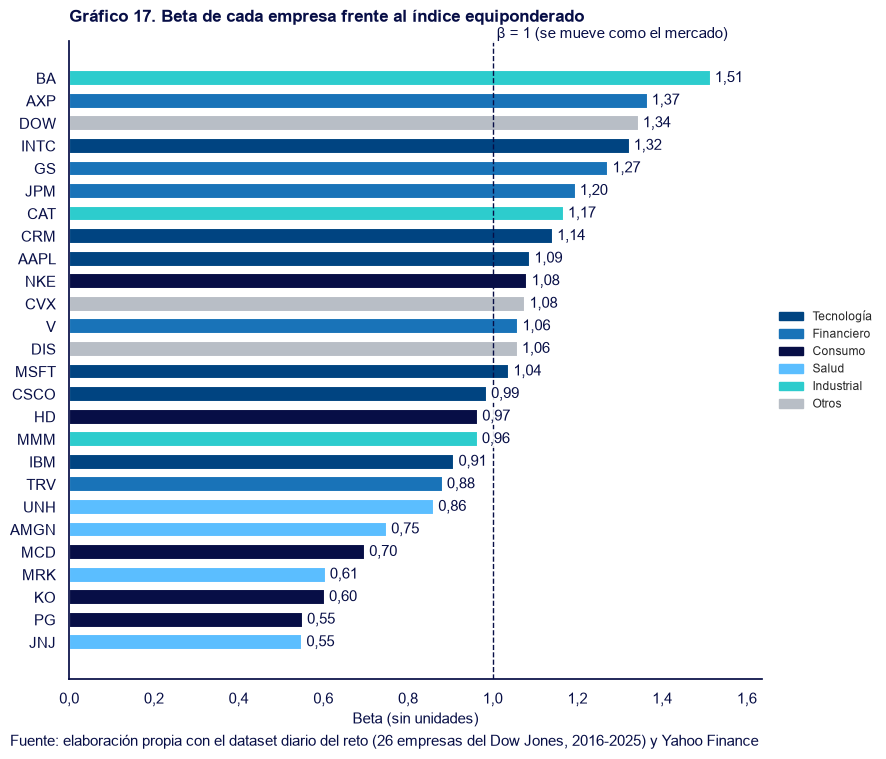

In [29]:
def beta_frente_a(r_empresa, r_referencia):
    datos = pd.concat([r_empresa, r_referencia], axis=1).dropna()
    y, x = datos.iloc[:, 0], datos.iloc[:, 1]
    beta = y.cov(x) / x.var()
    return pd.Series({"beta": beta, "alfa_anual": (y.mean() - beta * x.mean()) * DIAS_ANIO,
                      "r2": y.corr(x) ** 2})


betas = rent.apply(lambda s: beta_frente_a(s, rent_mercado)).T
if dji is not None:
    rent_dji = dji.pct_change().dropna()
    betas["beta_dji"] = rent.apply(lambda s: beta_frente_a(s, rent_dji)["beta"])
betas = betas.sort_values("beta")
imprimir(betas.round(3).to_string())
imprimir(f"\nRiesgo sistemático medio (R²): {betas['r2'].mean():.0%}. "
      f"El resto ({1 - betas['r2'].mean():.0%}) es específico de cada empresa y se puede diversificar.")

fig, ax = plt.subplots(figsize=(9, 7.5))
barras = ax.barh(betas.index, betas["beta"], color=[color(t) for t in betas.index], height=0.7,
                 edgecolor=FONDO, linewidth=1.5)
ax.bar_label(barras, labels=[f"{v:.2f}" for v in betas["beta"]], padding=3, fontsize=11, color=TINTA_2)
ax.axvline(1, color=TINTA_2, lw=1, ls="--")
ax.text(1, 1.0, " β = 1 (se mueve como el mercado)", transform=ax.get_xaxis_transform(), fontsize=11,
        color=TINTA_2, va="bottom")
ax.grid(False)
ax.set_xlabel("Beta (sin unidades)")
ax.margins(x=0.08)
leyenda_sectores(ax)
ax.set_title("Gráfico 17. Beta de cada empresa frente al índice equiponderado", pad=14)
plt.tight_layout()
for t in ax.texts:
    t.set_bbox(dict(facecolor=FONDO, edgecolor="none", alpha=0.85, pad=1))
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g17_beta_por_empresa")
plt.show()

**Qué se observa:**
- **Defensivas y cíclicas.** Las betas van de 0,55 (JNJ y PG) a 1,51 (BA). Las seis más bajas (JNJ 0,55, PG 0,55, KO 0,60, MRK 0,61, MCD 0,70 y AMGN 0,75) son de salud y consumo, y UNH sigue (0,86). Las más altas son BA (1,51), AXP (1,37), DOW (1,34), INTC (1,32), GS (1,27), JPM (1,20) y CAT (1,17): financieras, industriales y alguna tecnológica. 14 de las 26 empresas tienen β > 1. Las grandes tecnológicas están cerca de 1 (MSFT 1,04, CSCO 0,99, IBM 0,91), salvo INTC (1,32), CRM (1,14) y AAPL (1,09).
- **Riesgo de mercado frente a riesgo propio.** El R² medio es del 43 %: un 57 % del riesgo de cada empresa es específico y se puede diversificar. Dependen más del mercado las financieras (V 61 %, JPM 61 %, AXP 60 %, GS 60 %); menos, las defensivas (MRK 23 %, PG 28 %, UNH 29 %, JNJ 29 %).
- **Alfa.** Los mayores son los de AAPL (+13,0 % anual), MSFT (+11,4 %) y CAT (+10,3 %), y los menores los de DOW (−20,5 %), DIS (−9,2 %), NKE (−9,2 %) e INTC (−8,9 %).
- El índice equiponderado incluye a cada empresa con un peso de 1/N, lo que sube un poco su beta y su R². Por eso se compara con la beta frente al `^DJI` (`beta_dji`), que es casi la misma (diferencias de 0,1 como máximo, la mayor en UNH).

# 11. Factores del mercado: análisis de componentes principales (PCA)

Muestra común: 2019-03-21 a 2025-12-31 (1706 sesiones)
Varianza explicada por los 5 primeros componentes: [43,9, 7,6, 5,8, 3,9, 3,3]


Guardado: Graficos\descriptivo_g18_componentes_principales.png


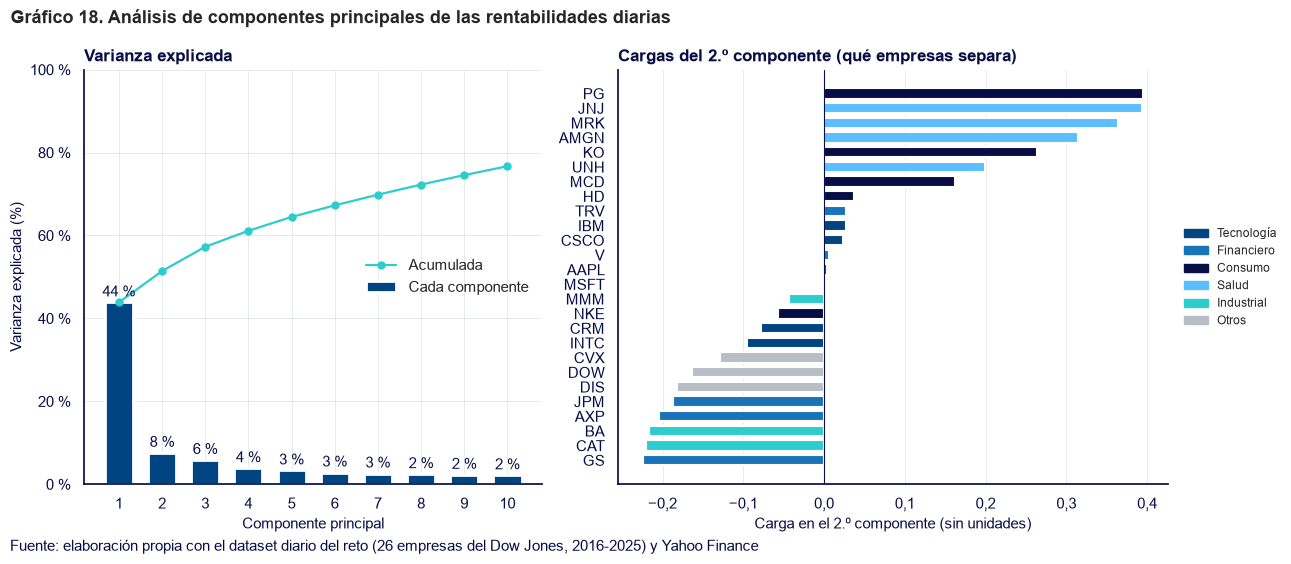

Cargas del 1.er componente (todas del mismo signo = factor mercado):
{'MRK': 0,142, 'UNH': 0,151, 'AMGN': 0,158, 'INTC': 0,161, 'JNJ': 0,164, 'CRM': 0,165, 'PG': 0,169, 'NKE': 0,184, 'BA': 0,191, 'MMM': 0,194, 'KO': 0,196, 'CVX': 0,198, 'TRV': 0,2, 'DIS': 0,201, 'IBM': 0,201, 'MSFT': 0,201, 'AAPL': 0,201, 'MCD': 0,203, 'CAT': 0,203, 'DOW': 0,205, 'CSCO': 0,208, 'HD': 0,214, 'GS': 0,235, 'V': 0,235, 'JPM': 0,236, 'AXP': 0,238}


In [30]:
# PCA sobre la matriz de correlaciones. Muestra común: desde que cotiza DOW (todas las empresas con datos)
cobertura = rent_log.notna().mean()
muestra = rent_log.loc[:, cobertura >= 0.5].dropna()      # empresas con al menos la mitad del historial
if (cobertura < 0.5).any():
    imprimir("Fuera del PCA por historial corto:", list(cobertura[cobertura < 0.5].index))
imprimir(f"Muestra común: {muestra.index[0].date()} a {muestra.index[-1].date()} ({len(muestra)} sesiones)")
autovalores, autovectores = np.linalg.eigh(np.corrcoef(muestra.values, rowvar=False))
orden = np.argsort(autovalores)[::-1]
autovalores, autovectores = autovalores[orden], autovectores[:, orden]
explicada = autovalores / autovalores.sum()
cargas = pd.DataFrame(autovectores[:, :3], index=muestra.columns, columns=["PC1", "PC2", "PC3"])
cargas = cargas * np.sign(cargas.mean())          # signo arbitrario: se orienta para que la media sea positiva
imprimir("Varianza explicada por los 5 primeros componentes:", (explicada[:5] * 100).round(1).tolist())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.2]})
k = 10
ax1.bar(range(1, k + 1), explicada[:k], color=AZUL, width=0.65, edgecolor=FONDO, linewidth=2,
        label="Cada componente")
ax1.plot(range(1, k + 1), np.cumsum(explicada[:k]), color=NARANJA, marker="o", ms=5, lw=1.6,
         label="Acumulada")
ax1.bar_label(ax1.containers[0], labels=[f"{v:.0%}" for v in explicada[:k]], padding=2, fontsize=11,
              color=TINTA_2)
eje_pct(ax1)
ax1.set_ylim(0, 1)
ax1.set_xticks(range(1, k + 1))
ax1.set_xlabel("Componente principal")
ax1.set_ylabel("Varianza explicada (%)")
ax1.legend(loc="center right")
ax1.set_title("Varianza explicada")

pc2 = cargas["PC2"].sort_values()
ax2.barh(pc2.index, pc2, color=[color(t) for t in pc2.index], height=0.7, edgecolor=FONDO, linewidth=1.5)
ax2.axvline(0, color=TINTA_2, lw=0.8)
ax2.grid(axis="y", visible=False)
leyenda_sectores(ax2)
ax2.set_xlabel("Carga en el 2.º componente (sin unidades)")
ax2.set_title("Cargas del 2.º componente (qué empresas separa)")
fig.suptitle("Gráfico 18. Análisis de componentes principales de las rentabilidades diarias", x=0.01, ha="left")
plt.tight_layout()
formato_es(fig, fuente=FUENTE)
guardar_mpl(fig, "descriptivo_g18_componentes_principales")
plt.show()

imprimir("Cargas del 1.er componente (todas del mismo signo = factor mercado):")
imprimir(cargas["PC1"].sort_values().round(3).to_dict())

**Qué se observa:**
- **Un único factor domina.** Con la muestra común de 1.706 sesiones (del 21/03/2019 al 31/12/2025, por el historial más corto de DOW), el 1.er componente explica el 43,9 % de la varianza y sus 26 cargas son positivas (de 0,14 a 0,24): es el factor mercado. Pesan más las financieras (AXP, JPM, V y GS, 0,235-0,238) y menos MRK (0,142), UNH (0,151) y AMGN (0,158). Los cinco primeros componentes explican el 64,5 % y los diez primeros, cerca del 77 %.
- **El 2.º componente (7,6 %)** separa las defensivas (PG, JNJ, MRK, AMGN, KO, UNH, con cargas de hasta +0,39) de las cíclicas (GS, CAT, BA, AXP, JPM, con cargas de ≈ −0,2).

# 12. Tabla resumen por empresa

In [31]:
resumen = pd.DataFrame({
    "nombre": pd.Series(NOMBRE),
    "sector": pd.Series({t: SUBSECTOR_OTROS.get(t, SECTOR[t]) for t in empresas}),
    "cagr": cagr_empresas,
    "volatilidad": vol_empresas,
    "sharpe": riesgo["sharpe"],
    "sortino": riesgo["sortino"],
    "max_drawdown": dd_empresas["max_drawdown"],
    "beta": betas["beta"],
    "r2_mercado": betas["r2"],
    "corr_media": fuera_diagonal.mean(),
    "carga_pc1": cargas["PC1"],
    "curtosis_exceso": tabla_r["curtosis_exceso"].drop("MERCADO").astype(float),
    "liquidez_musd": liquidez * 1000,
}).loc[empresas]
if yahoo_empresas is not None:
    resumen.insert(3, "cagr_con_dividendos", comparacion_div["cagr_total"])
resumen = resumen.sort_values("sharpe", ascending=False)
imprimir(resumen.round(3).to_string())

os.makedirs(RUTA_TRANSFORMADOS, exist_ok=True)
resumen.to_csv(f"{RUTA_TRANSFORMADOS}/resumen_descriptivo_empresas.csv", index_label="symbol")
imprimir("\nGuardado:", f"{RUTA_TRANSFORMADOS}/resumen_descriptivo_empresas.csv", resumen.shape)

                 nombre        sector   cagr  cagr_con_dividendos  volatilidad  sharpe  sortino  max_drawdown   beta  r2_mercado  corr_media  carga_pc1  curtosis_exceso  liquidez_musd
AAPL              Apple    Tecnología  0,263                0,276        0,290   0,877    1,294        -0,388  1,089       0,455       0,414      0,201            6,737       8978,279
MSFT          Microsoft    Tecnología  0,244                0,260        0,268   0,869    1,282        -0,376  1,039       0,489       0,430      0,201            7,908       5840,372
CAT         Caterpillar    Industrial  0,238                0,269        0,304   0,784    1,148        -0,462  1,168       0,478       0,420      0,203            4,876        597,264
V                  Visa    Financiero  0,166                0,174        0,245   0,662    0,958        -0,364  1,060       0,608       0,490      0,235           10,222       1322,350
JPM            JPMorgan    Financiero  0,176                0,208        0,276  

# Conclusiones

1. **Mercado.** El índice equiponderado de las 26 empresas rinde un 12,5 % anual (326 sobre base 100), por encima del Dow Jones real (10,9 %, 280), con el que comparte forma y caídas. Solo 2022 es un año negativo (−8,6 %); los otros episodios de caída (finales de 2018, COVID-19 y aranceles de 2025) se recuperaron antes de acabar el año.
2. **Dispersión.** Lo que se juega al elegir empresas es enorme: de +26,3 % anual (AAPL) a −10,5 % (DOW). Solo 8 de las 26 baten al índice: AAPL, MSFT, CAT, las financieras AXP, JPM, GS y V, y CRM. Ninguna empresa de salud ni de consumo supera al índice en rentabilidad anual compuesta. La cola mezcla sectores (DOW, NKE, INTC, DIS, MMM, BA).
3. **Riesgo.** La volatilidad media de las empresas es del 27,8 % frente al 18,1 % del mercado, y va por rachas: del 6,6 % en 2017 al 37,6 % en 2020. La mayor caída del mercado fue la del COVID-19 (−35,7 %, recuperada en 141 sesiones), pero la de 2022 (−22,7 %) fue la más lenta (479 sesiones). 11 empresas siguen más de un 20 % por debajo de su máximo a finales de 2025 (DOW, NKE, BA, UNH, INTC y DIS, las peores).
4. **Colas.** Las rentabilidades diarias están muy lejos de una normal: curtosis en exceso de 21 y 38 días de más de 3 desviaciones frente a 6,8 esperables. Los extremos se concentran en marzo de 2020 y, en los días extremos, casi todas las empresas se mueven en la misma dirección.
5. **Diversificación.** La correlación media es de 0,40 y el sector pesa (dentro de cada sector sube a 0,43-0,62). Pero la correlación media sube cuando sube la volatilidad (r = 0,82 entre ambas series) y alcanza su máximo en marzo de 2020, con más del doble de la media del periodo. Un único factor, el mercado, explica el 43,9 % de la varianza (PC1) y el 43 % del riesgo medio de cada empresa (R²). Salud es el sector menos correlacionado con el resto (0,32), y las seis betas más bajas (0,55-0,75) son de salud y consumo.
6. **Implicaciones para la cartera.** Los criterios de la tabla resumen que parecen más útiles para preseleccionar son: Sharpe alto (AAPL 0,88, MSFT 0,87, CAT 0,78), drawdown limitado y baja correlación con el resto. Las empresas con mejor rentabilidad ajustada al riesgo (AAPL, MSFT) están correlacionadas entre sí (0,68), así que conviene combinarlas con una defensiva poco correlacionada (como MRK, que aparece en los pares menos correlacionados). Habría que descartar a priori DOW, NKE, INTC, DIS, MMM y BA, con Sharpe bajo y drawdowns de entre −61 % y −78 %.

**Limitaciones que conviene tener presentes:**
- Las rentabilidades son de precio, sin dividendos (que aportan de media un 2,57 % anual, más en DOW, IBM y CVX).
- El universo son 26 empresas fijas, no la composición real del Dow en cada momento (sesgo de composición) y son miembros recientes del índice, lo que favorece a las que mejor lo han hecho (sesgo de supervivencia), y DOW solo cotiza desde 2019.
- Los resultados son de un único periodo (2016-2025), muy marcado por el COVID-19.